# Classical AI: Uncertain Knowledge and Reasoning

> **Who is this for?** Anyone who has finished the logic notebooks of this track (or simply knows Python basics) and wants to
> understand how an AI system reasons when it is **not sure**. It is also written for university students revising
> AIMA chapters 12 to 17 for an exam or an interview.
>
> **What you will learn**
> - why pure logic breaks down in the real world (the **qualification problem**)
> - joint distributions, marginalisation, conditioning, independence, conditional independence and Bayes' rule, all in code
> - naive Bayes as a reasoning engine (not just as a classifier)
> - **Bayesian networks**: structure, CPTs, the chain rule, d-separation, exact inference (enumeration and variable
>   elimination) and approximate inference (prior, rejection, likelihood weighting and Gibbs sampling)
> - temporal models: Markov chains and hidden Markov models (forward filtering, smoothing, Viterbi)
> - short notes on Kalman filters, Dempster-Shafer theory and certainty factors
> - decision theory: utility, expected utility, value of information, and a first look at MDPs
>
> **Prerequisites**
> - Python basics: [`../../01_Python/01_basic.ipynb`](../../01_Python/01_basic.ipynb)
> - Maths symbols explained in plain English: [`../../14_Mathematics/00_start_here_math_notation_bridge.ipynb`](../../14_Mathematics/00_start_here_math_notation_bridge.ipynb)
> - Probability recap (recommended): [`../../14_Mathematics/03_probability.ipynb`](../../14_Mathematics/03_probability.ipynb)
> - Helpful but optional: the logic notebooks earlier in this folder, [`07_knowledge_representation_and_logic.ipynb`](07_knowledge_representation_and_logic.ipynb) and [`08_reasoning_and_planning.ipynb`](08_reasoning_and_planning.ipynb)
>
> **Time needed:** about 2.5 to 3.5 hours (reading + running + practice problems).
>
> **Runs on:** CPU, no API key, no internet. Only `numpy`, `pandas`, `matplotlib` and `networkx`.
>
> **Optional track:** this notebook is part of the *university-level fundamentals track*. It is not required for the
> main path of the repo, but it is recommended for BS/MS AI students and for interview preparation.

## Explained simply

Real life is full of "probably": the bus is *probably* on time, the cough is *probably* just a cold. Plain logic only
knows "true" and "false", so it breaks when rules have exceptions. This notebook teaches a computer to reason with
**chances** instead: it keeps a number between 0 and 1 for how sure it is, and updates that number when new clues arrive.
A **Bayesian network** is a drawing of what causes what, plus a few small tables of chances; it lets the computer answer
questions like "the alarm rang and both neighbours called: how likely is a burglary?". The same ideas track things over
time (is it raining outside right now?) and help choose the action with the best expected result.

- **Everyday example 1:** a weather app saying "70% chance of rain" is a degree of belief, not a promise. You still decide
  whether to take an umbrella, and that decision depends on how much you hate getting wet (decision theory).
- **Everyday example 2:** a doctor does not jump to "you are sick" after one positive test. A rare disease stays fairly
  unlikely even after a positive result, because healthy people are so much more common (Bayes' rule).

**Tiny concrete example.** In a class of 100 students, 10 play the guitar. 8 of the 10 guitarists have calluses on their
fingertips, and so do 9 of the 90 others (from sports). You meet a student with calluses: of the 8 + 9 = 17 students with
calluses, 8 play guitar, so the chance is 8/17, about **47%**, not 80%.

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Bayes' rule | update how sure you are when a new clue arrives | medical tests, spam filters |
| Bayesian network | a cause-and-effect drawing with small tables of chances | fault diagnosis, risk models, causal AI |
| Hidden Markov model | guessing a hidden state from clues over time | speech recognition, GPS tracking |

## Table of contents
1. Why logic is not enough: the qualification problem
2. Probability recap in five minutes
3. The full joint distribution: marginalising, conditioning, normalising
4. Independence and conditional independence
5. Bayes' rule and a medical diagnosis example
6. Naive Bayes as a probabilistic reasoner
7. Bayesian networks: structure, CPTs, chain rule
8. d-separation: reading independence off the graph
9. Exact inference: enumeration and variable elimination
10. Approximate inference: prior, rejection, likelihood weighting, Gibbs
11. Temporal models: Markov chains and hidden Markov models
12. Kalman filters, Dempster-Shafer theory and certainty factors (brief)
13. Decision theory: utility, expected utility, value of information
14. A short introduction to MDPs
15. How this connects to modern AI, recap, practice problems, further reading

In [1]:
# Setup: imports and seeds used in the whole notebook
import itertools, math, random, time                 # standard library helpers
from collections import defaultdict, Counter         # handy containers
import numpy as np                                    # numeric arrays
import pandas as pd                                   # tables for traces
import matplotlib.pyplot as plt                       # plots
import networkx as nx                                 # graph drawing and d-separation check

random.seed(42)                                       # reproducible Python randomness
np.random.seed(42)                                    # reproducible numpy randomness
pd.set_option("display.precision", 4)                 # print tables with 4 decimals
pd.set_option("display.max_colwidth", 120)            # show long text columns in full
pd.set_option("display.width", 200)                   # wide tables on one line
print("networkx", nx.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

networkx 3.7 | numpy 2.4.6 | pandas 2.3.3


---
## 1. Why logic is not enough: the qualification problem

> 💡 **In plain English:** rules with exceptions break logic, so we measure how sure we are instead.

In propositional and first-order logic a rule is either true or false. Imagine a dentist writes the rule:

$$\text{Toothache} \Rightarrow \text{Cavity}$$

This rule is simply **wrong**: a toothache can also come from gum disease, an abscess, a cracked tooth... So we try:

$$\text{Toothache} \Rightarrow \text{Cavity} \lor \text{GumProblem} \lor \text{Abscess} \lor \dots$$

The list never ends. Turning it around (`Cavity ⇒ Toothache`) fails too: not every cavity hurts. To make a logical rule
exactly true you would have to list **every** exception ("...unless the patient took a painkiller, unless the cavity is
tiny, unless..."). This is the **qualification problem**: in real domains it is impossible to list all the
preconditions (qualifications) that a rule needs to be strictly true. Russell and Norvig (AIMA) give three reasons why
logic fails in domains like medicine:

| Reason | Meaning |
|---|---|
| **Laziness** | Listing all antecedents and consequents is too much work, and the rules would be too big to use. |
| **Theoretical ignorance** | Science has no complete theory of the domain. |
| **Practical ignorance** | Even with complete rules, we have not run every test on this particular patient. |

**Probability** is the tool that summarises this uncertainty. Instead of "toothache implies cavity" we say
"*given* a toothache, there is a **degree of belief** of 0.6 that there is a cavity". The 0.6 does not mean the tooth is
"60% decayed"; the tooth either has a cavity or not. It means: among patients like this one, about 60% have a cavity.

> ⚠️ **Common mistake: degree of belief vs. degree of truth.** Probability measures how *sure* we are about a fact that is
> either true or false. **Fuzzy logic** (next notebook) measures how *true* a vague statement is ("the room is warm" can
> be 0.7 true). They answer different questions and are not competitors.

---
## 2. Probability recap in five minutes

> 💡 **In plain English:** a quick reminder of the words and formulas we use for chances.

If any symbol below is new, read the [math notation bridge](../../14_Mathematics/00_start_here_math_notation_bridge.ipynb)
first; for a longer treatment see [`03_probability.ipynb`](../../14_Mathematics/03_probability.ipynb).

| Term | Precise definition | Example |
|---|---|---|
| **Sample space** $\Omega$ | the set of all possible worlds (complete outcomes) | all 8 combinations of Toothache, Catch, Cavity |
| **Random variable** | a function from worlds to values; its **domain** is the set of values it can take | `Cavity` with domain {true, false} |
| **Event / proposition** | a set of worlds | `cavity ∨ toothache` |
| **Axioms (Kolmogorov)** | $0 \le P(\omega) \le 1$, $\sum_{\omega} P(\omega) = 1$, and $P(a \lor b) = P(a) + P(b) - P(a \land b)$ | |
| **Prior (unconditional) probability** | belief before seeing evidence | $P(cavity) = 0.2$ |
| **Conditional probability** | $P(a \mid b) = \dfrac{P(a \land b)}{P(b)}$, defined when $P(b) > 0$ | $P(cavity \mid toothache) = 0.6$ |
| **Product rule** | $P(a \land b) = P(a \mid b)\,P(b)$ | |
| **Probability distribution** $\mathbf{P}(X)$ | the vector of probabilities of all values of $X$ (bold P) | $\mathbf{P}(Cavity) = \langle 0.2, 0.8\rangle$ |

Notation used below: lowercase `cavity` means `Cavity = true`, `¬cavity` means `Cavity = false`. A comma means AND:
$P(cavity, toothache) = P(cavity \land toothache)$.

---
## 3. The full joint distribution

> 💡 **In plain English:** list the chance of every possible world, then answer any question by adding rows.

**Intuition.** Picture a spreadsheet with one row for every possible world and the probability of that world in the last
column. If you have this sheet you can answer *any* question about the variables by adding up rows.

**Definition.** The **full joint probability distribution** $\mathbf{P}(X_1, \dots, X_n)$ assigns a probability to every
combination of values of all the variables.

The classic dentist example (AIMA, chapter 12) has three Boolean variables: `Toothache`, `Catch` (the dentist's steel
probe catches in the tooth) and `Cavity`:

|  | toothache, catch | toothache, ¬catch | ¬toothache, catch | ¬toothache, ¬catch |
|---|---|---|---|---|
| **cavity** | 0.108 | 0.012 | 0.072 | 0.008 |
| **¬cavity** | 0.016 | 0.064 | 0.144 | 0.576 |

**By hand:**
- **Marginalisation** (summing out): $P(cavity) = 0.108 + 0.012 + 0.072 + 0.008 = 0.2$.
  In general $\mathbf{P}(Y) = \sum_{z} \mathbf{P}(Y, z)$.
- **Any proposition**: $P(cavity \lor toothache) = 0.108 + 0.012 + 0.072 + 0.008 + 0.016 + 0.064 = 0.28$.
- **Conditioning**: $P(cavity \mid toothache) = \dfrac{0.108 + 0.012}{0.108 + 0.012 + 0.016 + 0.064} = \dfrac{0.12}{0.2} = 0.6$.
- **Normalisation**: notice that $P(cavity \mid toothache)$ and $P(\lnot cavity \mid toothache)$ share the
  denominator $P(toothache)$. So we can compute the unnormalised numbers $\langle 0.12, 0.08 \rangle$ and divide by
  their sum. We write this as $\mathbf{P}(Cavity \mid toothache) = \alpha \langle 0.12, 0.08 \rangle = \langle 0.6, 0.4\rangle$,
  where $\alpha$ is the **normalisation constant**.

The general recipe (**inference by enumeration over the joint**) for a query variable $X$, evidence $\mathbf{e}$ and hidden
(unobserved) variables $\mathbf{Y}$ is:

$$\mathbf{P}(X \mid \mathbf{e}) = \alpha\, \mathbf{P}(X, \mathbf{e}) = \alpha \sum_{\mathbf{y}} \mathbf{P}(X, \mathbf{e}, \mathbf{y})$$

In [2]:
# The dentist full joint distribution as a Python dict: (toothache, catch, cavity) -> probability
VARS = ("Toothache", "Catch", "Cavity")               # variable order inside each key
JOINT = {
    (True,  True,  True): 0.108, (True,  False, True): 0.012,
    (False, True,  True): 0.072, (False, False, True): 0.008,
    (True,  True,  False): 0.016, (True,  False, False): 0.064,
    (False, True,  False): 0.144, (False, False, False): 0.576,
}
assert abs(sum(JOINT.values()) - 1.0) < 1e-12        # axiom: probabilities of all worlds sum to 1

def world_dict(key):
    # turn a tuple key into {"Toothache": .., "Catch": .., "Cavity": ..}
    return dict(zip(VARS, key))

def prob(event):
    # P(event) = sum of P(world) over the worlds where event(world) is True
    return sum(p for key, p in JOINT.items() if event(world_dict(key)))

def cond_prob(event, given):
    # P(event | given) = P(event AND given) / P(given)
    return prob(lambda w: event(w) and given(w)) / prob(given)

def query(var, evidence):
    # P(var | evidence) as a distribution {True: .., False: ..}, computed with the alpha trick
    unnormalised = {}
    for value in (True, False):                      # for every value of the query variable
        unnormalised[value] = prob(lambda w: w[var] == value and all(w[k] == v for k, v in evidence.items()))
    alpha = 1.0 / sum(unnormalised.values())         # normalisation constant
    return {v: alpha * p for v, p in unnormalised.items()}

p_cavity = prob(lambda w: w["Cavity"])
p_cav_or_tooth = prob(lambda w: w["Cavity"] or w["Toothache"])
p_cav_given_tooth = cond_prob(lambda w: w["Cavity"], lambda w: w["Toothache"])
print(f"P(cavity)               = {p_cavity:.3f}")
print(f"P(cavity or toothache)  = {p_cav_or_tooth:.3f}")
print(f"P(cavity | toothache)   = {p_cav_given_tooth:.3f}")
print("P(Cavity | toothache)   =", {k: round(v, 3) for k, v in query("Cavity", {"Toothache": True}).items()})
print("P(Cavity | toothache, catch) =", {k: round(v, 3) for k, v in query("Cavity", {"Toothache": True, "Catch": True}).items()})
assert abs(p_cavity - 0.2) < 1e-12 and abs(p_cav_or_tooth - 0.28) < 1e-12 and abs(p_cav_given_tooth - 0.6) < 1e-12

P(cavity)               = 0.200
P(cavity or toothache)  = 0.280
P(cavity | toothache)   = 0.600
P(Cavity | toothache)   = {True: 0.6, False: 0.4}
P(Cavity | toothache, catch) = {True: 0.871, False: 0.129}


**What just happened?** We stored the 8 rows of the joint table and answered questions by adding rows. The results match
the hand calculation: 0.2, 0.28 and 0.6. Adding the second piece of evidence (the probe catches) raises the belief in a
cavity from 0.6 to about 0.871.

**Complexity.** With $n$ Boolean variables the table has $2^n$ rows, so storing it costs $O(2^n)$ space and answering a
query costs $O(2^n)$ time. For $n = 30$ that is over a billion numbers, which nobody can estimate from data or store.
This is why we need **independence** and, later, **Bayesian networks**.

---
## 4. Independence and conditional independence

> 💡 **In plain English:** some facts tell you nothing about each other, at least once you know the cause, and that makes tables tiny.

**Intuition.** Whether it rains in Lahore tomorrow tells you nothing about your tooth. Whether the probe catches *does*
tell you something about whether you have a toothache (both are symptoms of a cavity). But **once the dentist knows
whether there is a cavity**, the probe result tells nothing more about the toothache: both depend only on the cavity.

**Definitions.**
- $X$ and $Y$ are **independent**, written $X \perp Y$, if $\mathbf{P}(X, Y) = \mathbf{P}(X)\,\mathbf{P}(Y)$
  (equivalently $\mathbf{P}(X \mid Y) = \mathbf{P}(X)$).
- $X$ and $Y$ are **conditionally independent given $Z$**, written $X \perp Y \mid Z$, if
  $\mathbf{P}(X, Y \mid Z) = \mathbf{P}(X \mid Z)\,\mathbf{P}(Y \mid Z)$ for every value of $Z$.

**By hand** with the table above:
- $P(toothache, catch \mid cavity) = 0.108 / 0.2 = 0.54$, and $P(toothache \mid cavity)\,P(catch \mid cavity) = 0.6 \times 0.9 = 0.54$. Equal.
- $P(toothache, catch) = 0.124$, but $P(toothache)\,P(catch) = 0.2 \times 0.34 = 0.068$. Not equal.

So `Toothache` and `Catch` are **dependent**, but **conditionally independent given `Cavity`**. The code checks every
combination of values.

In [3]:
def is_independent(x, y, given=None, tol=1e-9):
    # Check P(X,Y | Z) == P(X|Z) P(Y|Z) for every value combination (Z may be None = marginal independence)
    z_values = [None] if given is None else [True, False]
    for z in z_values:
        cond = (lambda w: True) if given is None else (lambda w, z=z: w[given] == z)
        for xv in (True, False):
            for yv in (True, False):
                pxy = cond_prob(lambda w: w[x] == xv and w[y] == yv, cond)      # joint (conditional) probability
                px = cond_prob(lambda w: w[x] == xv, cond)                       # marginal of X
                py = cond_prob(lambda w: w[y] == yv, cond)                       # marginal of Y
                if abs(pxy - px * py) > tol:                                     # one mismatch is enough
                    return False
    return True

print("Toothache ⊥ Catch           :", is_independent("Toothache", "Catch"))
print("Toothache ⊥ Catch | Cavity  :", is_independent("Toothache", "Catch", given="Cavity"))
print("P(toothache, catch) =", round(prob(lambda w: w["Toothache"] and w["Catch"]), 3),
      " vs P(toothache) P(catch) =", round(prob(lambda w: w["Toothache"]) * prob(lambda w: w["Catch"]), 3))
assert not is_independent("Toothache", "Catch") and is_independent("Toothache", "Catch", given="Cavity")

# Why this matters: number of independent numbers needed
for n in (3, 10, 30):
    full = 2 ** n - 1                     # full joint over n Boolean variables (minus 1 because they sum to 1)
    naive = 1 + 2 * (n - 1)               # one cause + (n-1) effects each conditionally independent given the cause
    print(f"n={n:>2}: full joint needs {full:>13,} numbers, cause + conditionally independent effects need {naive}")

Toothache ⊥ Catch           : False
Toothache ⊥ Catch | Cavity  : True
P(toothache, catch) = 0.124  vs P(toothache) P(catch) = 0.068
n= 3: full joint needs             7 numbers, cause + conditionally independent effects need 5
n=10: full joint needs         1,023 numbers, cause + conditionally independent effects need 19
n=30: full joint needs 1,073,741,823 numbers, cause + conditionally independent effects need 59


**What just happened?** The checker confirmed what we computed by hand. The table shows the payoff: with one cause and
$n-1$ effects that are conditionally independent given the cause, we need $2n-1$ numbers instead of $2^n - 1$. Going from
**exponential** to **linear** is the whole reason probabilistic AI became practical.

> 🎓 **Exam / interview tip.** "Conditional independence does not imply independence, and independence does not imply
> conditional independence." Toothache and Catch are the first case. Burglary and Earthquake in section 8 are the second
> case: independent, but dependent once you hear the alarm.

---
## 5. Bayes' rule and a medical diagnosis example

> 💡 **In plain English:** turn "how often does the test say yes when sick" into "how likely am I sick, given the test said yes".

From the product rule written two ways, $P(a \land b) = P(a \mid b)P(b) = P(b \mid a)P(a)$, we get **Bayes' rule**:

$$P(\text{cause} \mid \text{effect}) = \frac{P(\text{effect} \mid \text{cause})\; P(\text{cause})}{P(\text{effect})}$$

**Why it is useful.** Doctors and test makers know the **causal** direction, $P(\text{positive test} \mid \text{disease})$
(the *sensitivity*), and the **prior** $P(\text{disease})$ (the *prevalence*). Patients want the **diagnostic** direction,
$P(\text{disease} \mid \text{positive test})$. Bayes' rule converts one into the other.

**Worked example by hand.** A disease affects 1% of people. A test has **sensitivity** 90% (it is positive for 90% of
sick people) and a **false positive rate** of 9% (it is positive for 9% of healthy people, so specificity is 91%).

| | count out of 100,000 | test positive | test negative |
|---|---|---|---|
| sick (1%) | 1,000 | 900 | 100 |
| healthy (99%) | 99,000 | 8,910 | 90,090 |

$$P(\text{sick} \mid +) = \frac{900}{900 + 8{,}910} = \frac{0.9 \times 0.01}{0.9 \times 0.01 + 0.09 \times 0.99} \approx 0.092$$

Only about **9%** of positive patients are sick. Most positives are false alarms because healthy people are so much
more common. Ignoring the prior is called the **base-rate fallacy**.

P(sick)                   = 0.0100
P(sick | one positive)    = 0.0917
P(sick | two positives)   = 0.5025   (assumes the two tests are conditionally independent given the disease)


simulated P(sick | +)     = 0.0917


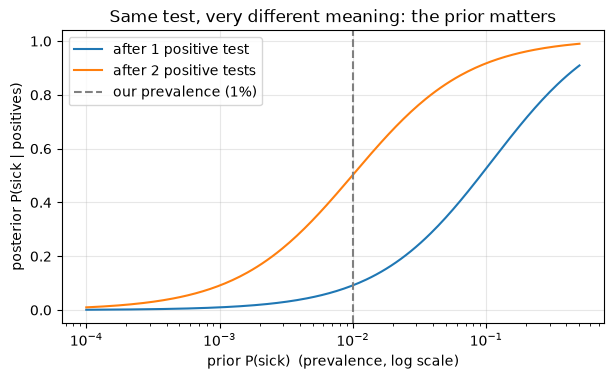

In [4]:
def posterior(prior, sensitivity, false_positive_rate):
    # Bayes' rule for a binary disease and a positive test result
    numerator = sensitivity * prior                              # P(+ | sick) P(sick)
    evidence = numerator + false_positive_rate * (1 - prior)     # P(+) by the law of total probability
    return numerator / evidence

prior, sens, fpr = 0.01, 0.90, 0.09
p1 = posterior(prior, sens, fpr)                                 # after one positive test
p2 = posterior(p1, sens, fpr)                                    # yesterday's posterior is today's prior
print(f"P(sick)                   = {prior:.4f}")
print(f"P(sick | one positive)    = {p1:.4f}")
print(f"P(sick | two positives)   = {p2:.4f}   (assumes the two tests are conditionally independent given the disease)")

# Check with a simulation of 1,000,000 people (natural frequencies)
rng = np.random.default_rng(0)
sick = rng.random(1_000_000) < prior                              # who is sick
test = np.where(sick, rng.random(sick.size) < sens, rng.random(sick.size) < fpr)   # their test results
print(f"simulated P(sick | +)     = {sick[test].mean():.4f}")
assert abs(sick[test].mean() - p1) < 0.01 and abs(p1 - 0.0917) < 1e-3

# How the posterior depends on the prior (prevalence)
priors = np.logspace(-4, -0.3, 200)
plt.figure(figsize=(7, 3.8))
plt.semilogx(priors, [posterior(p, sens, fpr) for p in priors], label="after 1 positive test")
plt.semilogx(priors, [posterior(posterior(p, sens, fpr), sens, fpr) for p in priors], label="after 2 positive tests")
plt.axvline(prior, color="grey", ls="--", label="our prevalence (1%)")
plt.xlabel("prior P(sick)  (prevalence, log scale)"); plt.ylabel("posterior P(sick | positives)")
plt.title("Same test, very different meaning: the prior matters"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

**What just happened?** One positive test moves the belief from 1% to about 9.2%, and a second independent positive test
moves it to about 50%. The simulation of a million people agrees with the formula. The plot shows that the *same* test is
almost useless for a rare disease and very informative for a common one.

**Complexity.** One application of Bayes' rule is $O(k)$ for a cause with $k$ values (compute $k$ numerators and
normalise).

> ⚠️ **Common mistake.** Confusing $P(+ \mid \text{sick})$ (90%) with $P(\text{sick} \mid +)$ (9%). This is sometimes
> called the *prosecutor's fallacy* in law.

---
## 6. Naive Bayes as a probabilistic reasoner

> 💡 **In plain English:** one cause, many symptoms: multiply the chance of each symptom you saw and compare the causes.

**Intuition.** One hidden cause (which illness?) produces several visible effects (symptoms). If we assume the symptoms
are **conditionally independent given the cause**, the full joint becomes a short product:

$$\mathbf{P}(Cause, e_1, \dots, e_n) = \mathbf{P}(Cause) \prod_{i} P(e_i \mid Cause)
\quad\Rightarrow\quad
\mathbf{P}(Cause \mid \text{observed } e) = \alpha\, \mathbf{P}(Cause) \prod_{i\ \text{observed}} P(e_i \mid Cause)$$

This is the **naive Bayes model**. It is "naive" because the assumption is often false (fever and fatigue are
correlated even given flu), yet its rankings are often good. A nice property for *reasoning*: symptoms we did not ask
about are simply left out of the product, because summing an unobserved symptom over its values gives 1.

You may know naive Bayes as a text classifier ([`06_naive_bayes.ipynb`](../../03_Machine_Learning/01_supervised/06_naive_bayes.ipynb)).
Here we use the same model as a small **diagnostic reasoner**, with numbers written by an "expert".

In [5]:
# A tiny diagnostic naive Bayes model (illustrative numbers, not medical advice)
CAUSES = ["flu", "cold", "allergy", "healthy"]
PRIOR = {"flu": 0.05, "cold": 0.20, "allergy": 0.10, "healthy": 0.65}
# P(symptom = present | cause)
LIKELIHOOD = {
    "fever":      {"flu": 0.90, "cold": 0.20, "allergy": 0.02, "healthy": 0.01},
    "cough":      {"flu": 0.80, "cold": 0.70, "allergy": 0.30, "healthy": 0.05},
    "sneezing":   {"flu": 0.30, "cold": 0.80, "allergy": 0.90, "healthy": 0.05},
    "itchy_eyes": {"flu": 0.05, "cold": 0.10, "allergy": 0.80, "healthy": 0.02},
    "fatigue":    {"flu": 0.90, "cold": 0.40, "allergy": 0.20, "healthy": 0.10},
}

def naive_bayes_posterior(observed):
    # observed: dict symptom -> True/False; unobserved symptoms are simply skipped
    log_scores = {}
    for c in CAUSES:
        s = math.log(PRIOR[c])                                        # work in logs to avoid underflow
        for symptom, present in observed.items():
            p = LIKELIHOOD[symptom][c]
            s += math.log(p if present else 1 - p)                    # P(e_i | c) or P(not e_i | c)
        log_scores[c] = s
    m = max(log_scores.values())                                       # log-sum-exp trick for stable normalising
    unnorm = {c: math.exp(s - m) for c, s in log_scores.items()}
    z = sum(unnorm.values())
    return {c: v / z for c, v in unnorm.items()}

def brute_force_posterior(observed):
    # Build the FULL joint of (cause, all 5 symptoms) from the same model and sum out unobserved symptoms
    symptoms = list(LIKELIHOOD)
    scores = defaultdict(float)
    for c in CAUSES:
        for values in itertools.product([True, False], repeat=len(symptoms)):   # 32 symptom worlds per cause
            w = dict(zip(symptoms, values))
            if any(w[s] != v for s, v in observed.items()):                       # inconsistent with evidence
                continue
            p = PRIOR[c]
            for s in symptoms:
                p *= LIKELIHOOD[s][c] if w[s] else 1 - LIKELIHOOD[s][c]
            scores[c] += p
    z = sum(scores.values())
    return {c: scores[c] / z for c in CAUSES}

patients = {
    "A: fever, cough, no sneezing":  {"fever": True, "cough": True, "sneezing": False},
    "B: sneezing, itchy eyes":       {"sneezing": True, "itchy_eyes": True},
    "C: cough only":                 {"cough": True},
    "D: nothing asked yet":          {},
}
rows = []
for name, obs in patients.items():
    nbp, bfp = naive_bayes_posterior(obs), brute_force_posterior(obs)
    assert all(abs(nbp[c] - bfp[c]) < 1e-12 for c in CAUSES)       # skipping unobserved symptoms is exact
    rows.append({"patient": name, **{c: nbp[c] for c in CAUSES}, "most likely": max(nbp, key=nbp.get)})
pd.DataFrame(rows).set_index("patient")

,flu,cold,allergy,healthy,most likely
patient,,,,,
"A: fever, cough, no sneezing",0.8085,0.1797,0.0019,0.0099,flu
"B: sneezing, itchy eyes",0.0084,0.1790,0.8054,0.0073,allergy
C: cough only,0.1649,0.5773,0.1237,0.1340,cold
D: nothing asked yet,0.0500,0.2000,0.1000,0.6500,healthy


**What just happened?** For each patient we multiplied the prior by the likelihood of every *observed* symptom and
normalised. The assert proves that this shortcut gives exactly the same answer as building the full joint of all 160
worlds (4 causes × 32 symptom combinations) and summing out the unobserved symptoms. Patient A is most likely to have the
flu (about 0.81), patient B an allergy (about 0.81), patient C a cold (about 0.58), and patient D (no evidence) gets the prior back.

**Complexity.** $O(|C| \cdot k)$ time for $|C|$ causes and $k$ observed symptoms, and $O(|C| \cdot n)$ numbers to store,
compared with $O(|C| \cdot 2^n)$ for the full joint.

---
## 7. Bayesian networks: structure, CPTs and the chain rule

> 💡 **In plain English:** draw arrows from causes to effects and give each node a small table; together they describe everything.

**Intuition.** Draw an arrow from every cause to its direct effects. Then, for each variable, write down how it depends
on its direct causes only. That small drawing plus a few small tables describes the whole joint distribution.

**Definition.** A **Bayesian network** (belief network) is
1. a **directed acyclic graph** (DAG) whose nodes are random variables, and
2. for each node $X_i$, a **conditional probability table (CPT)** $\mathbf{P}(X_i \mid Parents(X_i))$.

The network defines the joint distribution by the **chain rule factorisation**:

$$P(x_1, \dots, x_n) = \prod_{i=1}^{n} P\big(x_i \mid parents(X_i)\big)$$

This is correct because of the **local Markov property**: each node is conditionally independent of its
non-descendants given its parents. (The general chain rule $P(x_1..x_n) = \prod_i P(x_i \mid x_1..x_{i-1})$ always holds;
the network says that, in a topological order, only the parents matter.)

### The classic burglary network (Pearl; AIMA chapter 13)
You have a new burglar alarm at home. It is fairly reliable at detecting a **B**urglary, but it also goes off sometimes
for minor **E**arthquakes. Your neighbours **J**ohn and **M**ary promised to call you at work when they hear the
**A**larm. John sometimes confuses the telephone ringing with the alarm; Mary listens to loud music and sometimes misses it.

```
   Burglary        Earthquake          P(B) = 0.001        P(E) = 0.002
        \            /
         v          v                   B  E | P(A)          A | P(J)       A | P(M)
           Alarm                        T  T | 0.95          T | 0.90       T | 0.70
         /       \                      T  F | 0.94          F | 0.05       F | 0.01
        v         v                     F  T | 0.29
   JohnCalls   MaryCalls                F  F | 0.001
```

**Parameter count.** A Boolean node with $k$ Boolean parents needs $2^k$ numbers. Here $1 + 1 + 4 + 2 + 2 = 10$ numbers,
versus $2^5 - 1 = 31$ for the full joint. With $n$ nodes and at most $k$ parents each: $O(n \cdot 2^k)$ instead of $O(2^n)$.

**By hand:** the probability that the alarm sounds, both neighbours call, and there is neither a burglary nor an earthquake:

$$P(j, m, a, \lnot b, \lnot e) = P(j \mid a)\,P(m \mid a)\,P(a \mid \lnot b, \lnot e)\,P(\lnot b)\,P(\lnot e)
= 0.90 \times 0.70 \times 0.001 \times 0.999 \times 0.998 \approx 0.000628$$

In [6]:
class BayesNet:
    # A Bayesian network over Boolean variables.
    # nodes: list of (name, parents, cpt) in TOPOLOGICAL order; cpt maps a tuple of parent values -> P(name = True)
    def __init__(self, nodes):
        self.variables = [name for name, _, _ in nodes]               # topological order
        self.parents = {name: list(par) for name, par, _ in nodes}
        self.cpt = {name: dict(cpt) for name, _, cpt in nodes}
        self.children = {v: [c for c in self.variables if v in self.parents[c]] for v in self.variables}
        for name in self.variables:                                    # sanity checks on the CPTs
            par = self.parents[name]
            assert all(p in self.variables[: self.variables.index(name)] for p in par), "not topological"
            assert len(self.cpt[name]) == 2 ** len(par), f"CPT of {name} must have 2^k rows"
            assert all(0.0 <= q <= 1.0 for q in self.cpt[name].values())

    def p(self, var, value, assignment):
        # P(var = value | parents as in assignment)
        key = tuple(assignment[p] for p in self.parents[var])
        p_true = self.cpt[var][key]
        return p_true if value else 1.0 - p_true

    def joint(self, assignment):
        # chain rule: product of one CPT entry per variable
        result = 1.0
        for var in self.variables:
            result *= self.p(var, assignment[var], assignment)
        return result

T, F = True, False
burglary_net = BayesNet([
    ("Burglary",   [], {(): 0.001}),
    ("Earthquake", [], {(): 0.002}),
    ("Alarm",      ["Burglary", "Earthquake"], {(T, T): 0.95, (T, F): 0.94, (F, T): 0.29, (F, F): 0.001}),
    ("JohnCalls",  ["Alarm"], {(T,): 0.90, (F,): 0.05}),
    ("MaryCalls",  ["Alarm"], {(T,): 0.70, (F,): 0.01}),
])

def all_worlds(bn):
    # every complete assignment of the network's variables
    for values in itertools.product([True, False], repeat=len(bn.variables)):
        yield dict(zip(bn.variables, values))

p_example = burglary_net.joint({"Burglary": F, "Earthquake": F, "Alarm": T, "JohnCalls": T, "MaryCalls": T})
total = sum(burglary_net.joint(w) for w in all_worlds(burglary_net))
print(f"P(j, m, a, ¬b, ¬e) = {p_example:.6f}")
print(f"sum over all 32 worlds = {total:.12f}  (a valid distribution)")
n_params = sum(len(c) for c in burglary_net.cpt.values())
print(f"numbers in the CPTs = {n_params}   vs full joint = {2 ** len(burglary_net.variables) - 1}")
assert abs(total - 1) < 1e-12 and abs(p_example - 0.000628) < 1e-6

P(j, m, a, ¬b, ¬e) = 0.000628
sum over all 32 worlds = 1.000000000000  (a valid distribution)
numbers in the CPTs = 10   vs full joint = 31


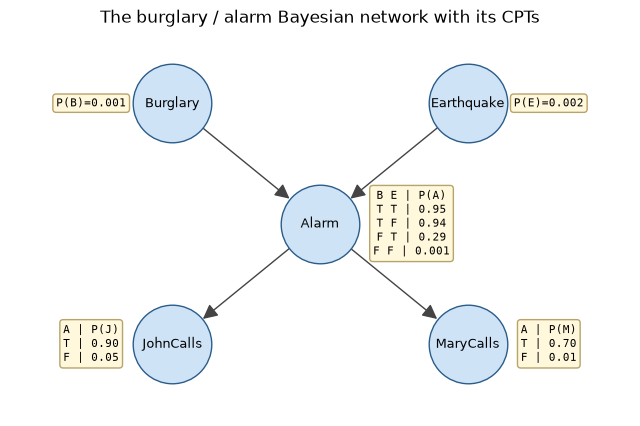

In [7]:
# Draw the burglary network with its CPTs next to each node
G = nx.DiGraph([(p, c) for c in burglary_net.variables for p in burglary_net.parents[c]])
pos = {"Burglary": (0, 2), "Earthquake": (2, 2), "Alarm": (1, 1), "JohnCalls": (0, 0), "MaryCalls": (2, 0)}
cpt_text = {
    "Burglary": "P(B)=0.001", "Earthquake": "P(E)=0.002",
    "Alarm": "B E | P(A)\nT T | 0.95\nT F | 0.94\nF T | 0.29\nF F | 0.001",
    "JohnCalls": "A | P(J)\nT | 0.90\nF | 0.05", "MaryCalls": "A | P(M)\nT | 0.70\nF | 0.01",
}
offset = {"Burglary": (-0.55, 0.0), "Earthquake": (0.55, 0.0), "Alarm": (0.62, 0.0),
          "JohnCalls": (-0.55, 0.0), "MaryCalls": (0.55, 0.0)}
fig, ax = plt.subplots(figsize=(8, 5))
nx.draw_networkx_nodes(G, pos, node_size=3200, node_color="#cfe3f7", edgecolors="#2b5d8a", ax=ax)
nx.draw_networkx_labels(G, pos, font_size=9, ax=ax)
nx.draw_networkx_edges(G, pos, arrowsize=22, node_size=3200, edge_color="#444", ax=ax)
for node, text in cpt_text.items():
    x, y = pos[node]; dx, dy = offset[node]
    ax.text(x + dx, y + dy, text, ha="center", va="center", family="monospace", fontsize=8,
            bbox=dict(boxstyle="round", fc="#fff8dc", ec="#b8a36a"))
ax.set_xlim(-1.1, 3.1); ax.set_ylim(-0.6, 2.6); ax.axis("off")
ax.set_title("The burglary / alarm Bayesian network with its CPTs")
plt.show()

**What just happened?** The `BayesNet` class stores the graph and the CPTs and computes any full-world probability with
the chain rule. The 32 world probabilities add up to 1, so 10 numbers really do define a complete joint distribution,
and $P(j, m, a, \lnot b, \lnot e) \approx 0.000628$ as computed by hand.

> ⚠️ **Common mistake: arrows are not "always causal".** The chain rule works for *any* DAG that respects the
> independencies, so you could build the network in the order MaryCalls, JohnCalls, Alarm, Burglary, Earthquake. It is
> still correct but needs more links and harder-to-estimate numbers (AIMA shows it needs 13 numbers instead of 10).
> Building in **causal order** gives the smallest and most natural networks.

---
## 8. d-separation: reading independence off the graph

> 💡 **In plain English:** read off the drawing which facts can influence each other, without any arithmetic.

**Intuition.** Think of influence as water flowing along the edges (in either direction). Observing a variable can open
or close a valve. If every path between $X$ and $Y$ is closed, then $X$ and $Y$ are independent given what we observed.

There are only **three kinds of connection** of a middle node $M$ on a path:

| Shape | Picture | Blocked when | Example in the burglary net |
|---|---|---|---|
| **Chain** (causal) | `X → M → Y` | $M$ **is** observed | Burglary → Alarm → JohnCalls: once you know the alarm, John's call says nothing more about a burglary |
| **Fork** (common cause) | `X ← M → Y` | $M$ **is** observed | JohnCalls ← Alarm → MaryCalls: the calls are correlated, but not once the alarm state is known |
| **Collider** (v-structure, common effect) | `X → M ← Y` | $M$ **and all its descendants are NOT** observed | Burglary → Alarm ← Earthquake: independent causes become dependent once you hear the alarm (or a call) |

**Definition.** A path between $X$ and $Y$ is **blocked** by a set of observed nodes $Z$ if it contains a chain or
fork whose middle node is in $Z$, or a collider such that neither the collider nor any of its descendants is in $Z$.
$X$ and $Y$ are **d-separated** by $Z$ if *every* path between them is blocked. **Theorem:** if $X$ and $Y$ are
d-separated by $Z$, then $X \perp Y \mid Z$ in every distribution that the network can represent.

The collider case is called **explaining away**: if the alarm rang and you then learn there was an earthquake, a burglary
becomes *less* likely, because the earthquake already explains the alarm.

Below are two independent implementations: the **path rules** above (list every path and check every triple), and the
**moral ancestral graph** criterion (Lauritzen): keep only $X$, $Y$, $Z$ and their ancestors, "marry" parents that share
a child, drop the arrow directions, delete $Z$, and check whether $X$ and $Y$ are still connected. We check both against
each other, against `networkx`, and against the numbers.

In [8]:
def descendants(bn, v):
    # all nodes reachable from v by following arrows forwards
    out, stack = set(), list(bn.children[v])
    while stack:
        c = stack.pop()
        if c not in out:
            out.add(c); stack.extend(bn.children[c])
    return out

def undirected_paths(bn, x, y):
    # all simple paths between x and y, ignoring arrow direction
    nbrs = {v: set(bn.parents[v]) | set(bn.children[v]) for v in bn.variables}
    def dfs(path):
        if path[-1] == y:
            yield list(path); return
        for n in nbrs[path[-1]]:
            if n not in path:
                yield from dfs(path + [n])
    yield from dfs([x])

def path_blocked(bn, path, z, explain=False):
    # check every consecutive triple (a, m, b) of the path with the three rules
    for a, m, b in zip(path, path[1:], path[2:]):
        collider = a in bn.parents[m] and b in bn.parents[m]          # a -> m <- b
        if collider:
            if m not in z and not (descendants(bn, m) & z):
                return f"collider {a}->{m}<-{b} with {m} and its descendants unobserved" if explain else True
        elif m in z:                                                   # chain or fork with observed middle
            return f"{'fork' if m in bn.parents[a] and m in bn.parents[b] else 'chain'} through observed {m}" if explain else True
    return False

def d_separated_paths(bn, x, y, z):
    return all(path_blocked(bn, p, set(z)) for p in undirected_paths(bn, x, y))

def d_separated_moral(bn, x, y, z):
    z = set(z)
    keep, stack = set(), [x, y, *z]                                    # 1. ancestral set of {x, y} ∪ z
    while stack:
        v = stack.pop()
        if v not in keep:
            keep.add(v); stack.extend(bn.parents[v])
    moral = nx.Graph(); moral.add_nodes_from(keep)
    for v in keep:                                                     # 2. moralise: link child-parent and co-parents
        ps = [p for p in bn.parents[v] if p in keep]
        moral.add_edges_from((p, v) for p in ps)
        moral.add_edges_from(itertools.combinations(ps, 2))
    moral.remove_nodes_from(z)                                         # 3. delete the observed nodes
    return not nx.has_path(moral, x, y)                                # 4. separated = no path left

examples = [("Burglary", "Earthquake", []), ("Burglary", "Earthquake", ["Alarm"]),
            ("Burglary", "Earthquake", ["JohnCalls"]), ("JohnCalls", "MaryCalls", []),
            ("JohnCalls", "MaryCalls", ["Alarm"]), ("Burglary", "JohnCalls", ["Alarm"]),
            ("Burglary", "MaryCalls", ["JohnCalls"])]
rows = []
for x, y, z in examples:
    reasons = [path_blocked(burglary_net, p, set(z), explain=True) for p in undirected_paths(burglary_net, x, y)]
    rows.append({"X": x, "Y": y, "given Z": ", ".join(z) or "(nothing)",
                 "d-separated?": d_separated_paths(burglary_net, x, y, z),
                 "why (per path)": "; ".join(r if r else "path is ACTIVE" for r in reasons)})
pd.DataFrame(rows)

,X,Y,given Z,d-separated?,why (per path)
0,Burglary,Earthquake,(nothing),True,collider Burglary->Alarm<-Earthquake with Alarm and its descendants unobserved
1,Burglary,Earthquake,Alarm,False,path is ACTIVE
2,Burglary,Earthquake,JohnCalls,False,path is ACTIVE
3,JohnCalls,MaryCalls,(nothing),False,path is ACTIVE
4,JohnCalls,MaryCalls,Alarm,True,fork through observed Alarm
5,Burglary,JohnCalls,Alarm,True,chain through observed Alarm
6,Burglary,MaryCalls,JohnCalls,False,path is ACTIVE


In [9]:
# Verification 1: the two d-separation algorithms and networkx agree on EVERY query in the burglary network
G_burglary = nx.DiGraph([(p, c) for c in burglary_net.variables for p in burglary_net.parents[c]])
checked = 0
for x, y in itertools.combinations(burglary_net.variables, 2):
    others = [v for v in burglary_net.variables if v not in (x, y)]
    for k in range(len(others) + 1):
        for z in itertools.combinations(others, k):
            a = d_separated_paths(burglary_net, x, y, z)
            b = d_separated_moral(burglary_net, x, y, z)
            c = nx.is_d_separator(G_burglary, {x}, {y}, set(z))
            assert a == b == c, (x, y, z)
            checked += 1
print("d-separation queries checked against networkx:", checked)

# Verification 2: compare with the actual numbers (independence tested on the joint distribution)
def joint_prob(bn, event):
    return sum(bn.joint(w) for w in all_worlds(bn) if event(w))

def numerically_independent(bn, x, y, z, tol=1e-12):
    for zv in itertools.product([True, False], repeat=len(z)):
        cond = dict(zip(z, zv))
        pz = joint_prob(bn, lambda w: all(w[k] == v for k, v in cond.items()))
        for xv, yv in itertools.product([True, False], repeat=2):
            pxyz = joint_prob(bn, lambda w: w[x] == xv and w[y] == yv and all(w[k] == v for k, v in cond.items()))
            pxz = joint_prob(bn, lambda w: w[x] == xv and all(w[k] == v for k, v in cond.items()))
            pyz = joint_prob(bn, lambda w: w[y] == yv and all(w[k] == v for k, v in cond.items()))
            if abs(pxyz * pz - pxz * pyz) > tol:                       # P(x,y|z) = P(x|z)P(y|z), multiplied out
                return False
    return True

agree = 0
for x, y in itertools.combinations(burglary_net.variables, 2):
    others = [v for v in burglary_net.variables if v not in (x, y)]
    for k in range(len(others) + 1):
        for z in itertools.combinations(others, k):
            assert d_separated_moral(burglary_net, x, y, z) == numerically_independent(burglary_net, x, y, list(z))
            agree += 1
print("queries where 'd-separated' == 'numerically independent':", agree, "of", checked)

# Explaining away in numbers
pb = joint_prob(burglary_net, lambda w: w["Burglary"])
pb_a = joint_prob(burglary_net, lambda w: w["Burglary"] and w["Alarm"]) / joint_prob(burglary_net, lambda w: w["Alarm"])
pb_ae = (joint_prob(burglary_net, lambda w: w["Burglary"] and w["Alarm"] and w["Earthquake"])
         / joint_prob(burglary_net, lambda w: w["Alarm"] and w["Earthquake"]))
print(f"P(b) = {pb:.4f} -> P(b | alarm) = {pb_a:.4f} -> P(b | alarm, earthquake) = {pb_ae:.4f}  (explained away)")

d-separation queries checked against networkx: 80


queries where 'd-separated' == 'numerically independent': 80 of 80
P(b) = 0.0010 -> P(b | alarm) = 0.3736 -> P(b | alarm, earthquake) = 0.0033  (explained away)


**What just happened?**
- The table shows the rules at work: Burglary and Earthquake are d-separated when nothing is observed (the only path
  goes through the unobserved collider Alarm), but become connected once we observe Alarm *or its descendant* JohnCalls.
- All 80 possible single-variable queries $(X, Y, Z)$ give the same answer with the path rules, with the moral-graph
  method and with `networkx.is_d_separator`.
- For this network, d-separation matches the *numbers* exactly: every d-separated pair is independent, and every
  d-connected pair really is dependent. (The theorem only guarantees the first direction; the second holds here because the
  CPT numbers are "generic". Special numbers can create extra independencies that the graph does not show.)
- **Explaining away:** a burglary goes from 0.001 to about 0.374 when the alarm rings, but drops to about 0.0033 once we
  also learn there was an earthquake.

**Complexity.** Listing all paths can be exponential in the worst case. The moral-graph method (or the linear-time
"Bayes-ball" reachability algorithm in Koller and Friedman) runs in $O(V + E)$.

> 🎓 **Exam / interview tip.** Learn the **Markov blanket** of a node: its parents, its children and its children's other
> parents. A node is conditionally independent of *all* other nodes given its Markov blanket. Gibbs sampling (section 10)
> relies on this.

---
## 9. Exact inference: enumeration and variable elimination

> 💡 **In plain English:** compute the precise answer by adding up the right products, cleverly reusing work.

**Task.** Compute the posterior $\mathbf{P}(X \mid \mathbf{e})$ for a query variable $X$ given evidence $\mathbf{e}$. The
classic question: *John and Mary both call. What is the probability of a burglary?*

### 9.1 Inference by enumeration
Write the query as a sum over the hidden variables (here $E$ and $A$) of the chain-rule product, and move each factor as
far left as possible:

$$\mathbf{P}(B \mid j, m) = \alpha \sum_{e} \sum_{a} P(B)\,P(e)\,P(a \mid B, e)\,P(j \mid a)\,P(m \mid a)
= \alpha\, P(B) \sum_{e} P(e) \sum_{a} P(a \mid B, e)\,P(j \mid a)\,P(m \mid a)$$

AIMA's `ENUMERATION-ASK` evaluates this expression tree depth-first. Answer: $\mathbf{P}(B \mid j, m) \approx \langle 0.284, 0.716 \rangle$.

**Complexity.** $O(2^n)$ time for $n$ Boolean variables (it visits a tree of all hidden-variable assignments), but only
$O(n)$ space (depth-first). It wastes time by recomputing the same sub-expressions, e.g. $P(j \mid a)P(m \mid a)$ for
every value of $e$.

In [10]:
def enumeration_ask(X, evidence, bn):
    # AIMA ENUMERATION-ASK: returns {True: P(X=true | e), False: P(X=false | e)}
    q = {}
    for x in (True, False):
        q[x] = enumerate_all(bn.variables, {**evidence, X: x}, bn)     # extend evidence with X = x
    z = q[True] + q[False]
    return {k: v / z for k, v in q.items()}                            # normalise (alpha)

def enumerate_all(variables, e, bn):
    if not variables:
        return 1.0
    Y, rest = variables[0], variables[1:]                              # variables are in topological order
    if Y in e:                                                         # Y has a value: one factor, no sum
        return bn.p(Y, e[Y], e) * enumerate_all(rest, e, bn)
    return sum(bn.p(Y, y, e) * enumerate_all(rest, {**e, Y: y}, bn)    # Y is hidden: sum over its values
               for y in (True, False))

ev = {"JohnCalls": True, "MaryCalls": True}
for X in ["Burglary", "Earthquake", "Alarm"]:
    r = enumeration_ask(X, ev, burglary_net)
    print(f"P({X:<10} = true | j, m) = {r[True]:.4f}")
assert abs(enumeration_ask("Burglary", ev, burglary_net)[True] - 0.284) < 1e-3

P(Burglary   = true | j, m) = 0.2842
P(Earthquake = true | j, m) = 0.1761
P(Alarm      = true | j, m) = 0.7607


### 9.2 Variable elimination (VE)
**Idea.** Do the sums **once**, from the inside out, and store the intermediate results in tables called **factors**
(dynamic programming). A **factor** $f(X_1, \dots, X_k)$ is just a table with one number per combination of values.
Two operations are enough:

- **Pointwise product** $f_1 \times f_2$: a new factor over the union of the variables, each entry is the product of the
  matching entries. Example: $f_1(A,B) \times f_2(B,C) = f_3(A,B,C)$ with $f_3(a,b,c) = f_1(a,b)\,f_2(b,c)$.
- **Summing out** a variable: $\sum_a f(A, B, C) = f'(B, C)$, adding the entries that differ only in $A$.

Algorithm: make one factor per CPT (with evidence values plugged in); for each hidden variable $H$ in some order,
multiply the factors that mention $H$ and sum $H$ out; finally multiply what is left and normalise.

**Hand trace for $\mathbf{P}(B \mid j, m)$, eliminating $A$ then $E$:**

| step | factors used | new factor |
|---|---|---|
| plug in evidence | $P(j \mid A) \to f_J(A)$, $P(m \mid A) \to f_M(A)$ | factors over $A$ only |
| eliminate $A$ | $f_A(A, B, E)$, $f_J(A)$, $f_M(A)$ | $f_1(B, E) = \sum_a f_A(a, B, E) f_J(a) f_M(a)$ |
| eliminate $E$ | $f_E(E)$, $f_1(B, E)$ | $f_2(B) = \sum_e f_E(e) f_1(B, e)$ |
| answer | $f_B(B) \times f_2(B)$, normalise | $\langle 0.284, 0.716 \rangle$ |

In [11]:
class Factor:
    # A table over Boolean variables: vars is a tuple, table maps a tuple of values -> number
    def __init__(self, vars, table):
        self.vars, self.table = tuple(vars), dict(table)

    def pointwise_product(self, other):
        new_vars = self.vars + tuple(v for v in other.vars if v not in self.vars)   # union, keep order
        table = {}
        for values in itertools.product([True, False], repeat=len(new_vars)):
            w = dict(zip(new_vars, values))
            table[values] = (self.table[tuple(w[v] for v in self.vars)]
                             * other.table[tuple(w[v] for v in other.vars)])
        return Factor(new_vars, table)

    def sum_out(self, var):
        i = self.vars.index(var)
        new_vars = self.vars[:i] + self.vars[i + 1:]
        table = defaultdict(float)
        for values, p in self.table.items():
            table[values[:i] + values[i + 1:]] += p                    # merge rows that differ only in var
        return Factor(new_vars, table)

    def normalise(self):
        z = sum(self.table.values())
        return Factor(self.vars, {k: v / z for k, v in self.table.items()})

def make_factor(var, evidence, bn):
    # the CPT of var as a factor over (var + parents) minus the evidence variables (whose values are fixed)
    scope = [v for v in [var] + bn.parents[var] if v not in evidence]
    table = {}
    for values in itertools.product([True, False], repeat=len(scope)):
        w = {**evidence, **dict(zip(scope, values))}
        table[values] = bn.p(var, w[var], w)
    return Factor(scope, table)

def elimination_ask(X, evidence, bn, order=None, trace=None):
    hidden = [v for v in bn.variables if v != X and v not in evidence]
    order = order or list(reversed(hidden))                            # AIMA default: reverse topological order
    factors = [make_factor(v, evidence, bn) for v in bn.variables]
    for h in order:
        related = [f for f in factors if h in f.vars]                  # factors that mention h
        product = related[0]
        for f in related[1:]:
            product = product.pointwise_product(f)
        new = product.sum_out(h)
        factors = [f for f in factors if h not in f.vars] + [new]
        if trace is not None:
            trace.append({"eliminate": h, "multiplied factors over": [list(f.vars) for f in related],
                          "new factor over": list(new.vars), "rows in biggest table": len(product.table)})
    result = factors[0]
    for f in factors[1:]:
        result = result.pointwise_product(f)
    result = result.normalise()
    return {x: result.table[(x,)] for x in (True, False)}

trace = []
ve = elimination_ask("Burglary", ev, burglary_net, trace=trace)
print(f"VE:          P(Burglary | j, m) = <{ve[True]:.4f}, {ve[False]:.4f}>")
en = enumeration_ask("Burglary", ev, burglary_net)
print(f"Enumeration: P(Burglary | j, m) = <{en[True]:.4f}, {en[False]:.4f}>")
pd.DataFrame(trace)

VE:          P(Burglary | j, m) = <0.2842, 0.7158>
Enumeration: P(Burglary | j, m) = <0.2842, 0.7158>


,eliminate,multiplied factors over,new factor over,rows in biggest table
0,Alarm,"[[Alarm, Burglary, Earthquake], [Alarm], [Alarm]]","[Burglary, Earthquake]",8
1,Earthquake,"[[Earthquake], [Burglary, Earthquake]]",[Burglary],4


In [12]:
# Exhaustive check: VE == enumeration == brute force over the full joint, for EVERY query variable and EVERY evidence set
def brute_force_ask(X, evidence, bn):
    num = {x: joint_prob(bn, lambda w, x=x: w[X] == x and all(w[k] == v for k, v in evidence.items()))
           for x in (True, False)}
    z = num[True] + num[False]
    return {x: num[x] / z for x in num}

n_checked, t_enum, t_ve = 0, 0.0, 0.0
for X in burglary_net.variables:
    others = [v for v in burglary_net.variables if v != X]
    for k in range(len(others) + 1):
        for ev_vars in itertools.combinations(others, k):
            for ev_vals in itertools.product([True, False], repeat=k):
                e = dict(zip(ev_vars, ev_vals))
                t0 = time.perf_counter(); a = enumeration_ask(X, e, burglary_net); t_enum += time.perf_counter() - t0
                t0 = time.perf_counter(); b = elimination_ask(X, e, burglary_net); t_ve += time.perf_counter() - t0
                c = brute_force_ask(X, e, burglary_net)
                assert abs(a[True] - b[True]) < 1e-12 and abs(a[True] - c[True]) < 1e-12, (X, e)
                # a different elimination order must give the same answer
                hidden = [v for v in burglary_net.variables if v != X and v not in e]
                d = elimination_ask(X, e, burglary_net, order=hidden)
                assert abs(d[True] - a[True]) < 1e-12
                n_checked += 1
print(f"{n_checked} queries: enumeration, variable elimination (2 orders) and brute force all agree.")
print(f"total time: enumeration {t_enum * 1000:.1f} ms, VE {t_ve * 1000:.1f} ms (tiny network, so overheads dominate)")

405 queries: enumeration, variable elimination (2 orders) and brute force all agree.
total time: enumeration 72.1 ms, VE 137.2 ms (tiny network, so overheads dominate)


**What just happened?** Variable elimination produced $\langle 0.284, 0.716\rangle$, exactly like enumeration. The trace
shows that eliminating `Alarm` first multiplied three factors into one table of 8 rows (over Alarm, Burglary,
Earthquake), then summed Alarm out. Then we checked **405 queries** (every query variable, every subset of evidence
variables, every combination of evidence values): enumeration, VE with two different elimination orders, and brute force
over the 32-world joint all agree to $10^{-12}$. On a 5-node network the Python overhead of building factors makes VE no
faster; its advantage shows on larger networks.

**Complexity of exact inference.**

| Method | Time | Space | Notes |
|---|---|---|---|
| Enumeration | $O(2^n)$ | $O(n)$ | recomputes repeated sub-expressions |
| Variable elimination | $O(n \cdot 2^{w+1})$, $w$ = induced width of the elimination order | same as time | linear in the size of a **polytree** (singly connected network) |
| Any exact method, general networks | NP-hard (in fact #P-hard) | | reduces from 3-SAT |

Choosing the best elimination order is itself NP-hard; in practice greedy heuristics (min-degree, min-fill) work well.
VE can also drop **irrelevant variables**: any variable that is not an ancestor of the query or the evidence can be removed
before inference (e.g. for $\mathbf{P}(J \mid b)$, `MaryCalls` is irrelevant).

> ⚠️ **Common mistake.** Forgetting to normalise at the end. The factor left after elimination is
> $\mathbf{P}(X, \mathbf{e})$, not $\mathbf{P}(X \mid \mathbf{e})$; its entries add up to $P(\mathbf{e})$.

---
## 10. Approximate inference by sampling

> 💡 **In plain English:** simulate the world many times and count; more simulations give a more accurate answer.

For large networks exact inference is too expensive, so we **simulate** the network many times and count. This is
**Monte Carlo** estimation; the error shrinks like $1/\sqrt{N}$ for $N$ samples.

| Method | How one sample is made | Estimate of $P(X = x \mid \mathbf{e})$ | Weakness |
|---|---|---|---|
| **Prior sampling** | sample every variable in topological order from its CPT | (no evidence) fraction of samples with $X = x$ | cannot handle evidence by itself |
| **Rejection sampling** | prior sample, **throw it away** if it disagrees with $\mathbf{e}$ | fraction among the kept samples | wastes $1 - P(\mathbf{e})$ of the samples; terrible for rare evidence |
| **Likelihood weighting** | **fix** evidence variables, sample the others; weight $w = \prod_{E_i \in \mathbf{e}} P(e_i \mid parents(E_i))$ | weighted fraction | weights can be tiny when the evidence is "downstream" and unlikely |
| **Gibbs sampling** (MCMC) | start anywhere; repeatedly resample one non-evidence variable from $P(X_i \mid \text{Markov blanket})$ | fraction of visited states | correlated samples, needs burn-in; slow mixing with near-deterministic CPTs |

For Gibbs we need $P(x_i \mid mb(X_i)) = \alpha\, P(x_i \mid parents(X_i)) \prod_{Y_j \in Children(X_i)} P(y_j \mid parents(Y_j))$.

All four are **consistent**: as $N \to \infty$ the estimate converges to the true value. Below we estimate
$P(\text{johnCalls})$ (no evidence, prior sampling) and $P(\text{burglary} \mid j, m)$ with the other three, and plot the
running estimate against the exact answer from section 9.

In [13]:
def prior_sample(bn, rng):
    # sample every variable in topological order from P(X | parents)
    x = {}
    for var in bn.variables:
        x[var] = rng.random() < bn.p(var, True, x)
    return x

def rejection_sampling(X, evidence, bn, n, rng):
    # returns the running estimate after each of the n generated samples (nan until the first one is accepted)
    counts, accepted, running = {True: 0, False: 0}, 0, []
    for _ in range(n):
        s = prior_sample(bn, rng)
        if all(s[k] == v for k, v in evidence.items()):                 # consistent with the evidence?
            counts[s[X]] += 1; accepted += 1
        running.append(counts[True] / accepted if accepted else float("nan"))
    return running, accepted

def weighted_sample(bn, evidence, rng):
    x, w = dict(evidence), 1.0
    for var in bn.variables:
        if var in evidence:
            w *= bn.p(var, evidence[var], x)                            # evidence fixed: multiply in its likelihood
        else:
            x[var] = rng.random() < bn.p(var, True, x)                  # others sampled as usual
    return x, w

def likelihood_weighting(X, evidence, bn, n, rng):
    wsum = {True: 0.0, False: 0.0}; running = []
    for _ in range(n):
        s, w = weighted_sample(bn, evidence, rng)
        wsum[s[X]] += w
        total = wsum[True] + wsum[False]
        running.append(wsum[True] / total if total > 0 else float("nan"))
    return running

def markov_blanket_prob_true(var, state, bn):
    # P(var = true | Markov blanket) using parents' CPT and children's CPTs
    score = {}
    for value in (True, False):
        s = dict(state); s[var] = value
        p = bn.p(var, value, s)
        for child in bn.children[var]:
            p *= bn.p(child, s[child], s)
        score[value] = p
    return score[True] / (score[True] + score[False])

def gibbs_ask(X, evidence, bn, n_sweeps, rng, burn_in=1000):
    nonevidence = [v for v in bn.variables if v not in evidence]
    state = dict(evidence)
    for v in nonevidence:
        state[v] = rng.random() < 0.5                                    # random initial state
    count_true, running = 0, []
    for sweep in range(burn_in + n_sweeps):
        for v in nonevidence:                                           # resample each variable in turn
            state[v] = rng.random() < markov_blanket_prob_true(v, state, bn)
        if sweep >= burn_in:                                            # discard burn-in sweeps
            count_true += state[X]
            running.append(count_true / (sweep - burn_in + 1))
    return running

N = 300_000
exact_j = brute_force_ask("JohnCalls", {}, burglary_net)[True]
exact_b = enumeration_ask("Burglary", ev, burglary_net)[True]

t0 = time.perf_counter()
rng = random.Random(1)
prior_running, cnt = [], 0
for i in range(N):                                                      # prior sampling for P(johnCalls)
    cnt += prior_sample(burglary_net, rng)["JohnCalls"]
    prior_running.append(cnt / (i + 1))
rej_running, n_acc = rejection_sampling("Burglary", ev, burglary_net, N, random.Random(2))
lw_running = likelihood_weighting("Burglary", ev, burglary_net, N, random.Random(3))
gibbs_running = gibbs_ask("Burglary", ev, burglary_net, 100_000, random.Random(4))
elapsed = time.perf_counter() - t0

results = pd.DataFrame([
    {"method": "prior sampling", "query": "P(johnCalls)", "samples": N, "estimate": prior_running[-1], "exact": exact_j},
    {"method": "rejection sampling", "query": "P(b | j, m)", "samples": f"{N} ({n_acc} kept)", "estimate": rej_running[-1], "exact": exact_b},
    {"method": "likelihood weighting", "query": "P(b | j, m)", "samples": N, "estimate": lw_running[-1], "exact": exact_b},
    {"method": "Gibbs sampling", "query": "P(b | j, m)", "samples": "100000 sweeps", "estimate": gibbs_running[-1], "exact": exact_b},
])
results["abs error"] = (results["estimate"] - results["exact"]).abs()
print(f"sampling time: {elapsed:.1f} s;  rejection kept {n_acc} of {N} samples = {n_acc / N:.4%} (P(j,m) = "
      f"{joint_prob(burglary_net, lambda w: w['JohnCalls'] and w['MaryCalls']):.4%})")
assert (results["abs error"] < 0.05).all()                               # all four within tolerance
assert abs(prior_running[-1] - exact_j) < 0.005
results

sampling time: 39.1 s;  rejection kept 627 of 300000 samples = 0.2090% (P(j,m) = 0.2084%)


,method,query,samples,estimate,exact,abs error
0,prior sampling,P(johnCalls),300000,0.0520,0.0521,0.0002
1,rejection sampling,"P(b | j, m)",300000 (627 kept),0.2982,0.2842,0.0141
2,likelihood weighting,"P(b | j, m)",300000,0.2615,0.2842,0.0227
3,Gibbs sampling,"P(b | j, m)",100000 sweeps,0.2855,0.2842,0.0013


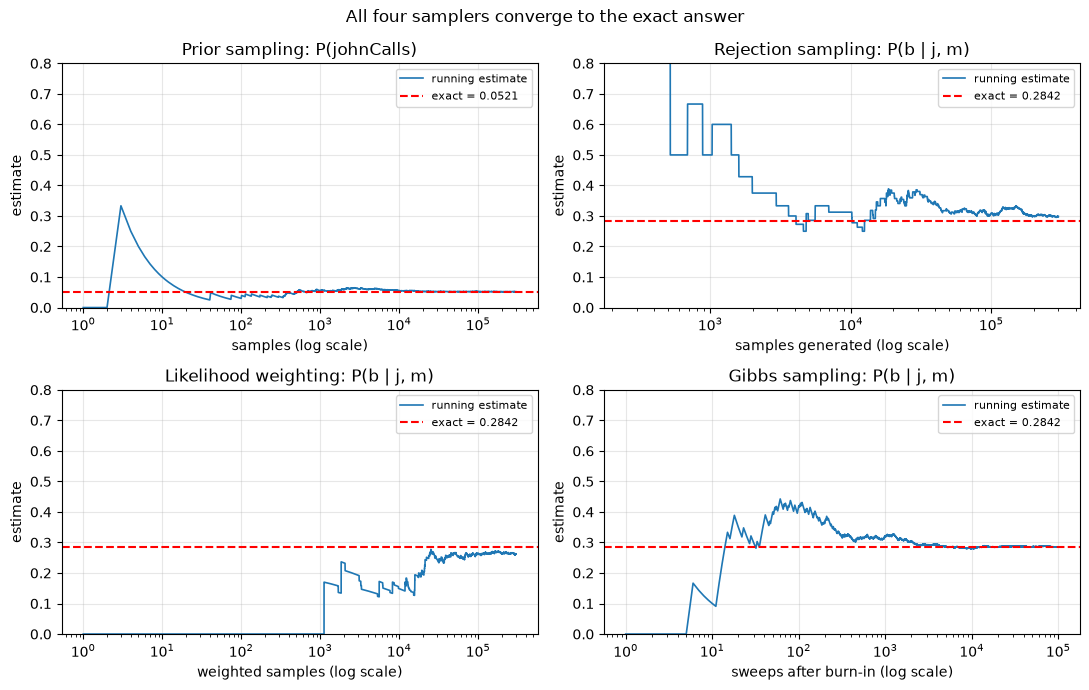

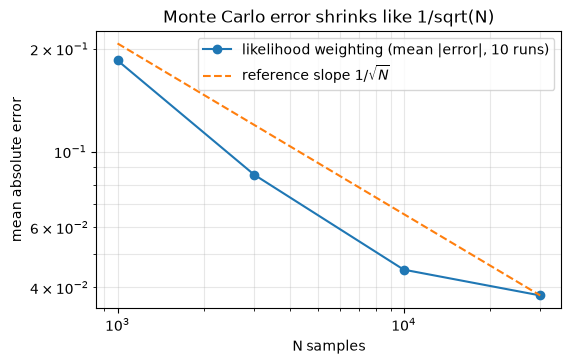

mean |error| per N: {1000: 0.185, 3000: 0.0856, 10000: 0.0451, 30000: 0.0379}


In [14]:
# Convergence plots: running estimate vs number of samples (log x axis)
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=False)
panels = [("Prior sampling: P(johnCalls)", prior_running, exact_j, "samples"),
          ("Rejection sampling: P(b | j, m)", rej_running, exact_b, "samples generated"),
          ("Likelihood weighting: P(b | j, m)", lw_running, exact_b, "weighted samples"),
          ("Gibbs sampling: P(b | j, m)", gibbs_running, exact_b, "sweeps after burn-in")]
for ax, (title, run, exact, xlabel) in zip(axes.ravel(), panels):
    xs = np.arange(1, len(run) + 1)
    ax.semilogx(xs, run, lw=1.2, label="running estimate")
    ax.axhline(exact, color="red", ls="--", label=f"exact = {exact:.4f}")
    ax.set_title(title); ax.set_xlabel(xlabel + " (log scale)"); ax.set_ylabel("estimate")
    ax.set_ylim(0, max(0.8, exact * 2)); ax.grid(alpha=0.3); ax.legend(loc="upper right", fontsize=8)
plt.suptitle("All four samplers converge to the exact answer")
plt.tight_layout(); plt.show()

# Error vs N for likelihood weighting over 10 independent runs: shrinks like 1/sqrt(N)
Ns = [1000, 3000, 10000, 30000]
errs = []
for n in Ns:
    runs = [likelihood_weighting("Burglary", ev, burglary_net, n, random.Random(100 + r))[-1] for r in range(10)]
    errs.append(np.mean([abs(r - exact_b) for r in runs if not math.isnan(r)]))
plt.figure(figsize=(6, 3.6))
plt.loglog(Ns, errs, "o-", label="likelihood weighting (mean |error|, 10 runs)")
plt.loglog(Ns, errs[-1] * np.sqrt(Ns[-1]) / np.sqrt(Ns), "--", label=r"reference slope $1/\sqrt{N}$")
plt.xlabel("N samples"); plt.ylabel("mean absolute error"); plt.title("Monte Carlo error shrinks like 1/sqrt(N)")
plt.legend(); plt.grid(alpha=0.3, which="both"); plt.show()
print("mean |error| per N:", {n: round(float(e), 4) for n, e in zip(Ns, errs)})

**What just happened?**
- **Prior sampling** estimates $P(\text{johnCalls}) \approx 0.052$ almost perfectly: no evidence, no waste.
- **Rejection sampling** kept only about 0.2% of its 300,000 samples (exactly the probability $P(j, m) \approx 0.0021$
  of the evidence), so its estimate is based on only about 600 samples and is the noisiest.
- **Likelihood weighting** uses every sample but most get a tiny weight (the alarm is rarely sampled true, and
  $P(j, m \mid \lnot a) = 0.0005$), so it also needs many samples.
- **Gibbs sampling** walks through states that agree with the evidence and settles near 0.284.
- The log-log plot shows the classic Monte Carlo law: 10 times more samples gives roughly $\sqrt{10} \approx 3.2$
  times less error (the measured errors are themselves noisy, since we average only 10 runs per point). (We start at 1,000 samples: with only a few hundred, most runs never sample the alarm at all, so they
  cannot see a burglary and the error does not shrink yet.)

**Complexity.** Each sample costs $O(n)$ (one CPT lookup per variable; for Gibbs, $O(\text{Markov blanket size})$ per
variable). The error is $O(1/\sqrt{N})$ *regardless of the network size*, which is why sampling scales where exact
inference cannot. For rejection sampling the useful sample count is $N \cdot P(\mathbf{e})$, which shrinks exponentially
with the number of evidence variables.

> 🎓 **Exam / interview tip.** "Why does likelihood weighting beat rejection sampling?" Because it never wastes a
> sample. "When is it still bad?" When the evidence is unlikely given the sampled upstream values, so almost all weight
> sits on a few samples (low *effective sample size*).

---
## 11. Temporal models: Markov chains and hidden Markov models

> 💡 **In plain English:** the hidden state changes over time and we only see clues; we keep updating our guess day by day.

The world changes over time. We index time steps $t = 0, 1, 2, \dots$ and write $X_t$ for the hidden state at time $t$
and $E_t$ for what we observe.

### 11.1 Markov chains
**Definition.** A **(first-order) Markov chain** satisfies the **Markov assumption**
$P(X_t \mid X_{0:t-1}) = P(X_t \mid X_{t-1})$: the future depends on the past only through the present. It is described
by a **transition matrix** $T_{ij} = P(X_t = j \mid X_{t-1} = i)$ (each row sums to 1). A distribution $\pi$ with
$\pi T = \pi$ is a **stationary distribution**.

**By hand.** Weather with states (sunny, rainy) and $T = \begin{pmatrix} 0.8 & 0.2 \\ 0.4 & 0.6 \end{pmatrix}$.
Stationarity gives $\pi_s = 0.8\pi_s + 0.4\pi_r$, so $0.2\pi_s = 0.4\pi_r$, $\pi_s = 2\pi_r$, and with
$\pi_s + \pi_r = 1$: $\pi = (2/3, 1/3)$. In the long run two days in three are sunny, whatever today's weather is.

after 15 days: [0.6667 0.3333] | eigenvector: [0.6667 0.3333] | simulated sunny share: 0.66724


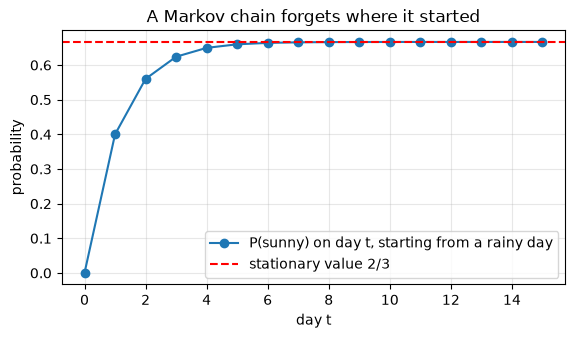

In [15]:
T_weather = np.array([[0.8, 0.2],      # from sunny: stay sunny 0.8, turn rainy 0.2
                      [0.4, 0.6]])     # from rainy: turn sunny 0.4, stay rainy 0.6
assert np.allclose(T_weather.sum(axis=1), 1.0)

# Power iteration: start rainy for sure and push the distribution forward day by day
dist = np.array([0.0, 1.0]); history = [dist]
for day in range(15):
    dist = dist @ T_weather                                              # P(X_t) = P(X_{t-1}) T
    history.append(dist)
history = np.array(history)

# Stationary distribution from the left eigenvector with eigenvalue 1
vals, vecs = np.linalg.eig(T_weather.T)
pi = np.real(vecs[:, np.argmin(abs(vals - 1))]); pi = pi / pi.sum()

# Simulation: fraction of sunny days in a long random walk
rng = np.random.default_rng(7); state, sunny = 1, 0
for _ in range(100_000):
    state = rng.choice(2, p=T_weather[state]); sunny += state == 0
print("after 15 days:", history[-1].round(4), "| eigenvector:", pi.round(4), "| simulated sunny share:", sunny / 100_000)
assert np.allclose(pi, [2 / 3, 1 / 3]) and np.allclose(history[-1], pi, atol=1e-4) and abs(sunny / 1e5 - 2 / 3) < 0.01

plt.figure(figsize=(6.5, 3.3))
plt.plot(history[:, 0], "o-", label="P(sunny) on day t, starting from a rainy day")
plt.axhline(2 / 3, color="red", ls="--", label="stationary value 2/3")
plt.xlabel("day t"); plt.ylabel("probability"); plt.title("A Markov chain forgets where it started")
plt.legend(); plt.grid(alpha=0.3); plt.show()

### 11.2 Hidden Markov models: the umbrella world
**Story (AIMA chapter 14).** You are a security guard in a windowless underground building. Each morning you see
whether the director comes in with an **umbrella** ($U_t$, observed). You want to know whether it is **raining** ($R_t$,
hidden).

**Definition.** A **hidden Markov model (HMM)** is a Markov chain over a hidden state, plus a **sensor model**
$P(E_t \mid X_t)$ (the **sensor Markov assumption**: the observation depends only on the current state).

```
   R0 ──> R1 ──> R2 ──> R3 ...      transition:  P(R_t | R_t-1) = 0.7,  P(R_t | ¬R_t-1) = 0.3
          │      │      │           sensor:      P(U_t | R_t)   = 0.9,  P(U_t | ¬R_t)   = 0.2
          v      v      v           prior:       P(R0) = 0.5
          U1     U2     U3
```

| Task | Question | Algorithm |
|---|---|---|
| **Filtering** | $\mathbf{P}(X_t \mid e_{1:t})$: belief about *now* | **forward** algorithm |
| **Smoothing** | $\mathbf{P}(X_k \mid e_{1:t})$, $k < t$: belief about the *past* | forward-backward |
| **Most likely explanation** | $\arg\max_{x_{1:t}} P(x_{1:t} \mid e_{1:t})$ | **Viterbi** |

**Forward algorithm (filtering), by hand.** Each step = *predict* with the transition model, then *update* with the
sensor model and normalise:

$$\mathbf{f}_{1:t+1} = \alpha\, P(e_{t+1} \mid X_{t+1}) \sum_{x_t} P(X_{t+1} \mid x_t)\, \mathbf{f}_{1:t}(x_t)$$

- Day 1, umbrella: predict $\langle 0.5, 0.5\rangle$; update $\alpha\langle 0.9 \times 0.5, 0.2 \times 0.5\rangle = \langle 0.818, 0.182\rangle$.
- Day 2, umbrella: predict $\langle 0.7 \times 0.818 + 0.3 \times 0.182,\ \dots\rangle = \langle 0.627, 0.373\rangle$;
  update $\alpha\langle 0.9 \times 0.627, 0.2 \times 0.373 \rangle = \langle 0.883, 0.117\rangle$.

**Viterbi** replaces the sum by a max and remembers which previous state gave the max (a back-pointer), then traces back
the best path. It is dynamic programming on a trellis, just like shortest paths.

In [16]:
STATES = [True, False]                                    # rain, no rain
PRIOR_R = {True: 0.5, False: 0.5}
TRANS = {True: {True: 0.7, False: 0.3}, False: {True: 0.3, False: 0.7}}   # TRANS[prev][next]
SENSOR = {True: {True: 0.9, False: 0.1}, False: {True: 0.2, False: 0.8}}  # SENSOR[state][umbrella]

def forward(evidence, TRANS=TRANS, SENSOR=SENSOR, PRIOR_R=PRIOR_R):
    # returns the list of filtered distributions f_{1:t} for t = 1..len(evidence)
    # (the model tables are parameters with the umbrella world as default, so we can reuse it for other HMMs)
    f, out = dict(PRIOR_R), []
    for e in evidence:
        predicted = {x: sum(TRANS[xp][x] * f[xp] for xp in STATES) for x in STATES}     # predict
        unnorm = {x: SENSOR[x][e] * predicted[x] for x in STATES}                       # update
        z = sum(unnorm.values())
        f = {x: unnorm[x] / z for x in STATES}                                          # normalise
        out.append(f)
    return out

def forward_backward(evidence, TRANS=TRANS, SENSOR=SENSOR, PRIOR_R=PRIOR_R):
    # smoothing: P(X_k | e_{1:t}) for every k, using forward messages and backward messages
    fwd = forward(evidence, TRANS, SENSOR, PRIOR_R)
    b, smoothed = {x: 1.0 for x in STATES}, [None] * len(evidence)
    for k in range(len(evidence) - 1, -1, -1):
        unnorm = {x: fwd[k][x] * b[x] for x in STATES}
        z = sum(unnorm.values()); smoothed[k] = {x: unnorm[x] / z for x in STATES}
        b = {xp: sum(SENSOR[x][evidence[k]] * b[x] * TRANS[xp][x] for x in STATES) for xp in STATES}  # backward step
        zb = sum(b.values()); b = {x: v / zb for x, v in b.items()}  # rescale: only ratios matter, avoids underflow
    return smoothed

def viterbi(evidence, TRANS=TRANS, SENSOR=SENSOR, PRIOR_R=PRIOR_R):
    # most likely sequence of hidden states; works with log probabilities
    m = {x: math.log(SENSOR[x][evidence[0]]) + math.log(sum(TRANS[x0][x] * PRIOR_R[x0] for x0 in STATES))
         for x in STATES}
    back = []
    for e in evidence[1:]:
        ptr, new_m = {}, {}
        for x in STATES:
            best_prev = max(STATES, key=lambda xp: m[xp] + math.log(TRANS[xp][x]))       # max instead of sum
            ptr[x] = best_prev
            new_m[x] = math.log(SENSOR[x][e]) + m[best_prev] + math.log(TRANS[best_prev][x])
        back.append(ptr); m = new_m
    last = max(STATES, key=m.get)                                                        # best final state
    path = [last]
    for ptr in reversed(back):                                                           # follow back-pointers
        path.append(ptr[path[-1]])
    return list(reversed(path)), m[last]

def brute_force_joint(states_seq, evidence):
    # P(x_1..x_t, e_1..e_t) with x_0 summed out
    total = 0.0
    for x0 in STATES:
        p, prev = PRIOR_R[x0], x0
        for x, e in zip(states_seq, evidence):
            p *= TRANS[prev][x] * SENSOR[x][e]; prev = x
        total += p
    return total

umbrellas = [True, True, False, True, True]
filt, smooth = forward(umbrellas), forward_backward(umbrellas)
best_path, best_log = viterbi(umbrellas)

# Brute-force verification over all 2^5 hidden sequences
seqs = list(itertools.product(STATES, repeat=len(umbrellas)))
for t in range(1, len(umbrellas) + 1):                                   # filtering at every time t
    prefixes = list(itertools.product(STATES, repeat=t))                 # all hidden sequences of length t
    num = sum(brute_force_joint(s, umbrellas[:t]) for s in prefixes if s[t - 1])
    den = sum(brute_force_joint(s, umbrellas[:t]) for s in prefixes)
    assert abs(filt[t - 1][True] - num / den) < 1e-12
for k in range(len(umbrellas)):                                          # smoothing at every k
    num = sum(brute_force_joint(s, umbrellas) for s in seqs if s[k])
    den = sum(brute_force_joint(s, umbrellas) for s in seqs)
    assert abs(smooth[k][True] - num / den) < 1e-12
def best_score(s):
    # P(x_1..x_t, e_1..e_t) with the day-0 state summed out (as in AIMA's Viterbi)
    return brute_force_joint(s, umbrellas)
bf_best = max(seqs, key=best_score)                                      # brute force over all 32 sequences
assert list(bf_best) == best_path and abs(math.log(best_score(bf_best)) - best_log) < 1e-9

pd.DataFrame({"day": range(1, 6), "umbrella": umbrellas,
              "filtered P(rain)": [f[True] for f in filt],
              "smoothed P(rain)": [s[True] for s in smooth],
              "Viterbi state": ["rain" if r else "no rain" for r in best_path]}).set_index("day")

,umbrella,filtered P(rain),smoothed P(rain),Viterbi state
day,,,,
1,True,0.8182,0.8673,rain
2,True,0.8834,0.8204,rain
3,False,0.1907,0.3075,no rain
4,True,0.7308,0.8204,rain
5,True,0.8673,0.8673,rain


**What just happened?**
- **Filtering** gives 0.818 on day 1 and 0.883 on day 2, exactly as by hand. On day 3 (no umbrella) the belief drops to
  about 0.19, then climbs back.
- **Smoothing** uses the whole week, so the belief about each day can be revised by later evidence (e.g. day 1 is
  revised upwards because day 2 also had an umbrella).
- **Viterbi** returns rain, rain, no rain, rain, rain: the single most likely sequence of days 1 to 5 (the unobserved
  day-0 state is summed out, as in AIMA).
- Every number was checked against brute force over all $2^5 = 32$ hidden sequences.

**Complexity.** Forward, forward-backward and Viterbi all run in $O(t \cdot S^2)$ time for $t$ steps and $S$ states
(brute force is $O(S^t)$). Filtering needs $O(S)$ memory (only the last message); smoothing and Viterbi need $O(t \cdot S)$.

Below we simulate 30 days of weather and watch the filter track the hidden rain.

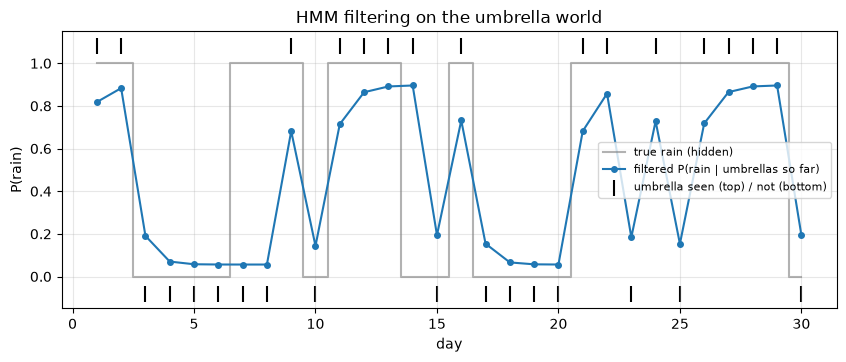

                            umbrella world (AIMA numbers)  sticky weather + noisy sensor
'umbrella means rain' rule                          0.850                          0.700
filtering (past + today)                            0.850                          0.747
smoothing (whole sequence)                          0.850                          0.791
Viterbi (best sequence)                             0.841                          0.759


In [17]:
rng = random.Random(11)
rain = [rng.random() < 0.5]
for _ in range(29):
    rain.append(rng.random() < TRANS[rain[-1]][True])                        # hidden weather
umb = [rng.random() < SENSOR[r][True] for r in rain]                          # what the guard sees
f30 = forward(umb); path30, _ = viterbi(umb)

days = np.arange(1, 31)
plt.figure(figsize=(10, 3.6))
plt.step(days, rain, where="mid", color="grey", alpha=0.6, label="true rain (hidden)")
plt.plot(days, [f[True] for f in f30], "o-", ms=4, label="filtered P(rain | umbrellas so far)")
plt.scatter(days, [1.08 if u else -0.08 for u in umb], marker="|", s=120, color="black", label="umbrella seen (top) / not (bottom)")
plt.xlabel("day"); plt.ylabel("P(rain)"); plt.ylim(-0.15, 1.15); plt.legend(fontsize=8, loc="center right")
plt.title("HMM filtering on the umbrella world"); plt.grid(alpha=0.3); plt.show()
# Long run: 10,000 simulated days, per-day accuracy of four ways to guess the hidden weather, in two worlds
def compare(trans, sensor, seed, days=10_000):
    rng = random.Random(seed)
    rain_l = [rng.random() < 0.5]
    for _ in range(days - 1):
        rain_l.append(rng.random() < trans[rain_l[-1]][True])           # hidden weather
    umb_l = [rng.random() < sensor[r][True] for r in rain_l]             # observations
    guesses = {
        "'umbrella means rain' rule": umb_l,
        "filtering (past + today)": [f[True] > 0.5 for f in forward(umb_l, trans, sensor)],
        "smoothing (whole sequence)": [s_[True] > 0.5 for s_ in forward_backward(umb_l, trans, sensor)],
        "Viterbi (best sequence)": viterbi(umb_l, trans, sensor)[0],
    }
    acc = {k: np.mean([g == r for g, r in zip(v, rain_l)]) for k, v in guesses.items()}
    return acc, guesses, umb_l

acc_aima, g_aima, umb_aima = compare(TRANS, SENSOR, seed=12)
STICKY = {True: {True: 0.9, False: 0.1}, False: {True: 0.1, False: 0.9}}      # weather changes rarely
NOISY = {True: {True: 0.75, False: 0.25}, False: {True: 0.35, False: 0.65}}   # unreliable director
acc_noisy, _, _ = compare(STICKY, NOISY, seed=13)
acc_table = pd.DataFrame({"umbrella world (AIMA numbers)": acc_aima,
                          "sticky weather + noisy sensor": acc_noisy})
print(acc_table.round(3).to_string())
assert g_aima["filtering (past + today)"] == umb_aima                    # explained in the text below
assert acc_noisy["smoothing (whole sequence)"] == max(acc_noisy.values())
assert acc_noisy["filtering (past + today)"] > acc_noisy["'umbrella means rain' rule"] + 0.03

**What just happened?** The filter follows the hidden weather well; it is only fooled when the director's behaviour is
unusual. The long-run table (10,000 simulated days per world) holds a surprise worth understanding:
- In the **AIMA umbrella world**, filtering makes exactly the same yes/no guesses as the rule "umbrella means rain"
  (0.85 accuracy for both, and smoothing scores the same). One observation is stronger than the memory of yesterday: an
  umbrella multiplies the odds of rain by $0.9/0.2 = 4.5$, while the prediction from yesterday can only give odds between
  $0.3/0.7 \approx 0.43$ and $0.7/0.3 \approx 2.3$. So today's observation always wins at the 0.5 threshold. The filter
  still adds value: it gives a calibrated *probability*, not just a yes/no.
- In a world with **sticky weather (0.9) and an unreliable director**, the HMM clearly wins: the rule gets 0.70,
  filtering about 0.75 and **smoothing** about 0.79, because smoothing also uses *tomorrow's* observation.
- **Viterbi** optimises the whole *sequence* at once, not each day separately, so its per-day accuracy is a little lower
  than smoothing's. Use it when you need one consistent story (e.g. the sequence of words in speech recognition).

> 🎓 **Exam / interview tip.** "What is the difference between filtering and Viterbi?" Filtering gives the most likely
> state *at each time separately* (a distribution per step); Viterbi gives the single most likely *sequence*. The two can
> disagree, because a sequence of individually likely states can be an unlikely sequence.

---
## 12. Brief notes: Kalman filters, Dempster-Shafer theory and certainty factors

> 💡 **In plain English:** three other ways people have handled uncertainty, and why probability mostly won.

### 12.1 Kalman filter (continuous HMM)
When the hidden state is **continuous** (a position, a speed) and both the transition and sensor models are **linear
with Gaussian noise**, the belief stays a Gaussian forever. The **Kalman filter** (Kalman, 1960) is then the exact
forward algorithm: it only has to track a mean and a variance. Each step:

- **predict**: $\mu^- = \mu$, $\sigma^{2-} = \sigma^2 + q$ (motion noise $q$ makes us less sure)
- **update**: gain $K = \sigma^{2-} / (\sigma^{2-} + r)$, $\mu = \mu^- + K\,(z - \mu^-)$, $\sigma^2 = (1 - K)\,\sigma^{2-}$
  (measurement noise $r$; a reliable sensor gives $K$ close to 1)

It guided the Apollo spacecraft and is still used in every GPS receiver, drone and self-driving car (in its extended
and unscented versions for non-linear models). A one-dimensional example:

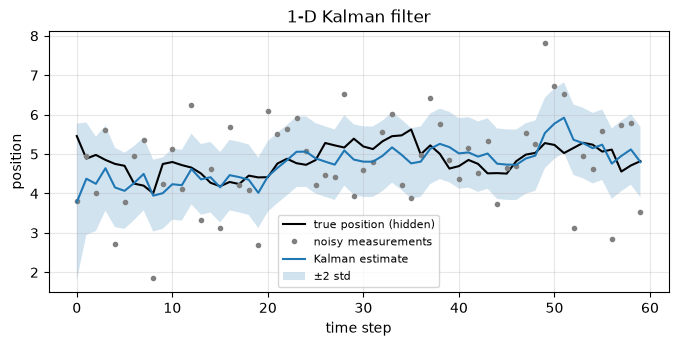

mean squared error: raw measurements 1.207, Kalman estimate 0.118 (after a 10-step warm-up)


In [18]:
rng = np.random.default_rng(3)
q, r, steps = 0.05, 1.0, 60                                     # motion noise variance, sensor noise variance
true_x = np.cumsum(rng.normal(0, math.sqrt(q), steps)) + 5.0     # hidden position: a slow random walk
z = true_x + rng.normal(0, math.sqrt(r), steps)                  # noisy GPS readings
mu, var, est, band = 0.0, 100.0, [], []                          # vague initial belief
for zi in z:
    var = var + q                                                # predict
    K = var / (var + r)                                          # Kalman gain
    mu = mu + K * (zi - mu); var = (1 - K) * var                 # update
    est.append(mu); band.append(2 * math.sqrt(var))
est, band = np.array(est), np.array(band)
mse_raw, mse_kf = np.mean((z - true_x) ** 2), np.mean((est[10:] - true_x[10:]) ** 2)
plt.figure(figsize=(8, 3.4))
plt.plot(true_x, label="true position (hidden)", color="black")
plt.plot(z, ".", color="grey", label="noisy measurements")
plt.plot(est, label="Kalman estimate"); plt.fill_between(range(steps), est - band, est + band, alpha=0.2, label="±2 std")
plt.xlabel("time step"); plt.ylabel("position"); plt.title("1-D Kalman filter"); plt.legend(fontsize=8); plt.grid(alpha=0.3)
plt.show()
print(f"mean squared error: raw measurements {mse_raw:.3f}, Kalman estimate {mse_kf:.3f} (after a 10-step warm-up)")
assert mse_kf < mse_raw

**What just happened?** The filter's estimate is much smoother and closer to the truth than the raw readings, and its
uncertainty band shrinks quickly from the vague start and then stays constant. Cost per step: $O(d^3)$ for a
$d$-dimensional state (matrix inverse), here $O(1)$.

### 12.2 Dempster-Shafer theory (historical alternative)
Dempster (1967) and Shafer (1976) wanted to separate "evidence against" from "lack of evidence". A **mass function**
$m$ assigns belief to *sets* of hypotheses (including the whole frame $\Theta$, meaning "I don't know"). From it:
**belief** $Bel(A) = \sum_{B \subseteq A} m(B)$ (evidence that surely supports $A$) and **plausibility**
$Pl(A) = \sum_{B \cap A \neq \emptyset} m(B) = 1 - Bel(\lnot A)$. The interval $[Bel, Pl]$ shows how much we do not know.
Two independent sources are combined with **Dempster's rule** $m_{12}(A) \propto \sum_{B \cap C = A} m_1(B)\, m_2(C)$,
renormalised to remove the conflict mass on $\emptyset$.

In [19]:
THETA = frozenset({"flu", "cold", "allergy"})
def combine(m1, m2):
    # Dempster's rule of combination
    out, conflict = defaultdict(float), 0.0
    for b, p in m1.items():
        for c, q2 in m2.items():
            inter = b & c
            if inter: out[inter] += p * q2
            else: conflict += p * q2                                 # mass on the empty set = conflict
    return {a: v / (1 - conflict) for a, v in out.items()}, conflict

bel = lambda m, a: sum(v for b, v in m.items() if b <= a)            # subsets of a
pl = lambda m, a: sum(v for b, v in m.items() if b & a)              # sets that overlap a
m_fever = {frozenset({"flu"}): 0.6, THETA: 0.4}                      # a fever points to flu, 40% uncommitted
m_sneeze = {frozenset({"cold", "allergy"}): 0.7, THETA: 0.3}         # sneezing points to cold-or-allergy
m, k = combine(m_fever, m_sneeze)
for h in ["flu", "cold", "allergy"]:
    print(f"{h:<8} Bel = {bel(m, frozenset({h})):.3f}   Pl = {pl(m, frozenset({h})):.3f}")
print(f"Bel(cold or allergy) = {bel(m, frozenset({'cold', 'allergy'})):.3f},  conflict between the sources = {k:.2f}")
assert abs(sum(m.values()) - 1) < 1e-12

flu      Bel = 0.310   Pl = 0.517
cold     Bel = 0.000   Pl = 0.690
allergy  Bel = 0.000   Pl = 0.690
Bel(cold or allergy) = 0.483,  conflict between the sources = 0.42


Note how DS theory gives `cold` a belief of 0 but a plausibility of 0.69: no evidence points to cold *alone*, but
nothing rules it out. The two sources also conflict a lot (0.42 of the combined mass fell on the empty set and was
renormalised away). Dempster's rule is known to behave strangely when sources strongly conflict (Zadeh's 1979
counter-example), and DS theory is not linked to decisions as cleanly as probability, so it remains a niche tool
(some sensor-fusion work).

### 12.3 Certainty factors (MYCIN, historical)
The MYCIN expert system (Stanford, 1970s, for blood infections) attached a **certainty factor** $CF \in [-1, 1]$ to each
rule and combined them with simple formulas (e.g. two positive pieces of evidence: $CF = CF_1 + CF_2(1 - CF_1)$).
It was fast and doctors understood it, and MYCIN performed comparably to specialists in an evaluation. But Heckerman
(1986) showed that CFs are only consistent with probability theory under strong independence assumptions, and with
overlapping evidence they double-count. Bayesian networks replaced them from the late 1980s. We implement CFs in the
[next notebook](10_fuzzy_logic_and_expert_systems.ipynb) on expert systems.

---
## 13. Decision theory: utility, expected utility, value of information

> 💡 **In plain English:** choose the action with the best average outcome, and pay for information only if it could change your choice.

Knowing probabilities is not enough; an agent must **act**.

**Definitions.**
- A **utility function** $U(s)$ gives a number to each outcome state: how much the agent likes it.
- The **expected utility** of an action $a$ given evidence $\mathbf{e}$ is
  $EU(a \mid \mathbf{e}) = \sum_{s'} P(\text{Result}(a) = s' \mid a, \mathbf{e})\; U(s')$.
- The **principle of maximum expected utility (MEU)**: a rational agent chooses $a^* = \arg\max_a EU(a \mid \mathbf{e})$.
  (The von Neumann and Morgenstern axioms show that any agent with consistent preferences behaves as if it maximises some
  utility function.)
- The **value of perfect information (VPI)** of a variable $E_j$ is how much more expected utility we would get if we
  knew $E_j$ before acting:
  $VPI(E_j) = \Big(\sum_k P(E_j = e_{jk})\, \max_a EU(a \mid E_j = e_{jk})\Big) - \max_a EU(a)$.
  VPI is **never negative** and **not additive**. Information is worth gathering when its value exceeds its cost.

**Worked example (umbrella decision).** $P(\text{rain}) = 0.3$. Utilities:

| action \ weather | rain | no rain |
|---|---|---|
| take umbrella | 80 | 70 |
| leave it | 0 | 100 |

- $EU(\text{take}) = 0.3 \times 80 + 0.7 \times 70 = 73$; $EU(\text{leave}) = 0.7 \times 100 = 70$. So take it (73).
- With **perfect** knowledge: if rain, take it (80); if not, leave it (100). $0.3 \times 80 + 0.7 \times 100 = 94$, so
  $VPI = 94 - 73 = 21$.
- A real **forecast** is right 80% of the time. Its value must be between 0 and 21. The code computes it.

without information: {'take': 73.0, 'leave': 70.0} -> choose take
forecast says rain (p=0.38): P(rain)=0.632 -> take, EU=76.32
forecast says dry  (p=0.62): P(rain)=0.097 -> leave, EU=90.32
EU no info = 73.00 | with forecast = 85.00 | with perfect info = 94.00
value of the forecast = 12.00,  value of perfect information = 21.00


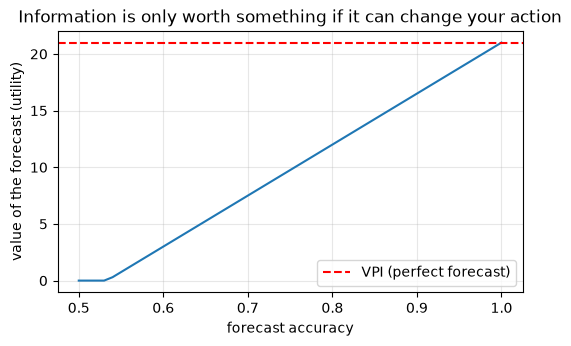

the forecast changes the decision (and has value > 0) only when its accuracy exceeds 0.533


In [20]:
P_RAIN = 0.3
U = {("take", True): 80, ("take", False): 70, ("leave", True): 0, ("leave", False): 100}
ACTIONS = ["take", "leave"]

def best_action(p_rain):
    eu = {a: p_rain * U[(a, True)] + (1 - p_rain) * U[(a, False)] for a in ACTIONS}
    a = max(eu, key=eu.get)
    return a, eu[a], eu

a0, eu0, all_eu = best_action(P_RAIN)
print("without information:", {k: round(v, 2) for k, v in all_eu.items()}, "-> choose", a0)

# Perfect information: we learn the weather, then act
eu_perfect = P_RAIN * max(U[(a, True)] for a in ACTIONS) + (1 - P_RAIN) * max(U[(a, False)] for a in ACTIONS)
vpi = eu_perfect - eu0

# Imperfect information: a forecast with accuracy 0.8 in both directions
acc = 0.8
p_says_rain = acc * P_RAIN + (1 - acc) * (1 - P_RAIN)                 # P(forecast = rain)
post_rain_if_says_rain = acc * P_RAIN / p_says_rain                    # Bayes' rule
post_rain_if_says_dry = (1 - acc) * P_RAIN / (1 - p_says_rain)
a_r, eu_r, _ = best_action(post_rain_if_says_rain)
a_d, eu_d, _ = best_action(post_rain_if_says_dry)
eu_forecast = p_says_rain * eu_r + (1 - p_says_rain) * eu_d
voi_forecast = eu_forecast - eu0

print(f"forecast says rain (p={p_says_rain:.2f}): P(rain)={post_rain_if_says_rain:.3f} -> {a_r}, EU={eu_r:.2f}")
print(f"forecast says dry  (p={1 - p_says_rain:.2f}): P(rain)={post_rain_if_says_dry:.3f} -> {a_d}, EU={eu_d:.2f}")
print(f"EU no info = {eu0:.2f} | with forecast = {eu_forecast:.2f} | with perfect info = {eu_perfect:.2f}")
print(f"value of the forecast = {voi_forecast:.2f},  value of perfect information = {vpi:.2f}")
assert 0 <= voi_forecast <= vpi and abs(vpi - 21) < 1e-9 and abs(eu0 - 73) < 1e-9

# VOI of the forecast as a function of its accuracy
accs = np.linspace(0.5, 1.0, 51); vois = []
for a_ in accs:
    ps = a_ * P_RAIN + (1 - a_) * (1 - P_RAIN)
    v = ps * best_action(a_ * P_RAIN / ps)[1] + (1 - ps) * best_action((1 - a_) * P_RAIN / (1 - ps))[1] - eu0
    vois.append(v)
plt.figure(figsize=(6, 3.4)); plt.plot(accs, vois); plt.axhline(vpi, ls="--", color="red", label="VPI (perfect forecast)")
plt.xlabel("forecast accuracy"); plt.ylabel("value of the forecast (utility)"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Information is only worth something if it can change your action"); plt.show()
threshold = (0.3 - 0.3 * 30 / 110) / (0.3 - 0.3 * 30 / 110 + 0.7 * 30 / 110)        # solve P(rain | "dry") = 30/110
print(f"the forecast changes the decision (and has value > 0) only when its accuracy exceeds {threshold:.3f}")
assert all(v < 1e-9 for a_, v in zip(accs, vois) if a_ < threshold - 1e-9) and all(v > 0 for a_, v in zip(accs, vois) if a_ > threshold + 1e-9)

**What just happened?** Without information the agent takes the umbrella (EU 73). The 80%-accurate forecast changes the
decision when it says "dry", raising the expected utility to 85, so the forecast is worth **12** utility units; perfect
information would be worth 21. The plot shows that a forecast with accuracy below about 0.53 is worth **nothing**
here, because it never changes the decision: even when it says "dry", rain stays likely enough that taking the umbrella
is still best. (Leaving the umbrella is only better when $P(\text{rain}) < 30/110 \approx 0.27$.) That is the key insight of value of information: *information has value only if
it can change what you do*.

> ⚠️ **Common mistake.** Utility is not the same as money. Most people are **risk-averse**: they prefer a sure $500 to a
> 50/50 chance of $1,000 or $0, which means their utility of money is concave (e.g. logarithmic).

---
## 14. A short introduction to Markov decision processes (MDPs)

> 💡 **In plain English:** many decisions in a row, where each one changes what happens next.

Section 13 was a **one-shot** decision. When the agent acts repeatedly and each action changes the state, we need a
**Markov decision process**: states $S$, actions $A$, a transition model $P(s' \mid s, a)$, a reward $R(s, a, s')$ and a
discount factor $\gamma \in [0, 1)$. The best possible expected discounted reward from each state, $U^*(s)$, satisfies the
**Bellman equation**

$$U^*(s) = \max_a \sum_{s'} P(s' \mid s, a)\,\big[R(s, a, s') + \gamma\, U^*(s')\big]$$

**Value iteration** turns this equation into an update rule and repeats until the values stop changing (it converges
because the update is a contraction for $\gamma < 1$). A tiny example: a delivery van that is `good`, `worn` or `broken`.

In [21]:
S = ["good", "worn", "broken"]
A = ["drive", "service"]
# P[(s, a)] = {s': probability};  R[(s, a)] = immediate reward (profit of the day)
P = {("good", "drive"): {"good": 0.8, "worn": 0.2}, ("good", "service"): {"good": 1.0},
     ("worn", "drive"): {"worn": 0.6, "broken": 0.4}, ("worn", "service"): {"good": 1.0},
     ("broken", "drive"): {"broken": 1.0}, ("broken", "service"): {"good": 1.0}}
R = {("good", "drive"): 100, ("good", "service"): -20, ("worn", "drive"): 80, ("worn", "service"): -20,
     ("broken", "drive"): -50, ("broken", "service"): -200}
gamma = 0.9

U_ = {s: 0.0 for s in S}
for iteration in range(1000):
    new = {s: max(R[(s, a)] + gamma * sum(p * U_[s2] for s2, p in P[(s, a)].items()) for a in A) for s in S}
    delta = max(abs(new[s] - U_[s]) for s in S); U_ = new
    if delta < 1e-9:
        break
policy = {s: max(A, key=lambda a: R[(s, a)] + gamma * sum(p * U_[s2] for s2, p in P[(s, a)].items())) for s in S}
print(f"converged after {iteration + 1} iterations")
print("values :", {s: round(v, 1) for s, v in U_.items()})
print("policy :", policy)
# The Bellman equation holds at the fixed point
for s in S:
    assert abs(U_[s] - max(R[(s, a)] + gamma * sum(p * U_[s2] for s2, p in P[(s, a)].items()) for a in A)) < 1e-6

converged after 239 iterations
values : {'good': 816.9, 'worn': 715.3, 'broken': 535.3}
policy : {'good': 'drive', 'worn': 'service', 'broken': 'service'}


**What just happened?** Value iteration found that the van should keep driving while it is `good`, get serviced as soon
as it is `worn` (a breakdown is expensive), and of course be repaired when `broken`. Each iteration costs
$O(|S|^2 |A|)$.

When the transition model is **unknown**, the agent must learn by trial and error: that is **reinforcement learning**.
Continue with [`../../11_Reinforcement_Learning/01_rl_fundamentals.ipynb`](../../11_Reinforcement_Learning/01_rl_fundamentals.ipynb)
and [`02_dynamic_programming.ipynb`](../../11_Reinforcement_Learning/02_dynamic_programming.ipynb). Partially observable
MDPs (POMDPs) combine this section with the HMM filtering of section 11: the agent acts on its *belief state*.

---
## 15. Summary comparison table

> 💡 **In plain English:** all the methods of this notebook side by side.

| Method | Exact? | Time | Typical use |
|---|---|---|---|
| Full joint enumeration | yes | $O(2^n)$ | teaching, tiny problems |
| Naive Bayes | yes (for its model) | $O(\lvert C \rvert k)$ | spam filters, quick diagnosis, baselines |
| BN enumeration | yes | $O(2^n)$, $O(n)$ space | small networks |
| Variable elimination | yes | exponential in induced width | medium networks, polytrees in linear time |
| Rejection / likelihood weighting | approximate | $O(nN)$, error $O(1/\sqrt{N})$ | large networks, easy evidence |
| Gibbs sampling (MCMC) | approximate | $O(N \cdot \text{blanket})$ per sweep | large networks, Bayesian statistics |
| HMM forward / Viterbi | yes | $O(tS^2)$ | speech, part-of-speech tagging, bioinformatics |
| Kalman filter | yes (linear-Gaussian) | $O(td^3)$ | tracking, navigation, sensor fusion |

## 🔗 How this connects to modern AI
- **Probabilistic machine learning.** Bayesian networks are the ancestor of probabilistic graphical models and of
  today's probabilistic programming languages (Stan, PyMC, Pyro, NumPyro), whose samplers (e.g. Hamiltonian Monte Carlo)
  are descendants of the Gibbs sampler above. See [`../../14_Mathematics/07_bayesian_ml.ipynb`](../../14_Mathematics/07_bayesian_ml.ipynb).
- **Causal inference.** d-separation is the foundation of Pearl's causal graphs, back-door adjustment and the "do"
  calculus: [`../../03_Machine_Learning/10_causal_inference/01_causal_inference.ipynb`](../../03_Machine_Learning/10_causal_inference/01_causal_inference.ipynb).
- **Sequence models.** HMMs with Viterbi decoding ran speech recognition and part-of-speech tagging for decades before
  neural networks; Viterbi-style dynamic programming and beam search still decode CTC speech models and LLM outputs
  ([`../../07_NLP/08_speech_and_audio.ipynb`](../../07_NLP/08_speech_and_audio.ipynb)).
- **Robotics and self-driving.** Kalman and particle filters (sampling for temporal models) fuse GPS, IMU, lidar and camera data.
- **Calibrated predictions.** A classifier's output is only usable for expected-utility decisions if its probabilities are
  calibrated: [`../../03_Machine_Learning/01_supervised/13_model_calibration.ipynb`](../../03_Machine_Learning/01_supervised/13_model_calibration.ipynb).
- **Decision theory and RL.** MEU is the objective behind RL agents, recommender systems and A/B-test decisions;
  value of information drives active learning ([`../../03_Machine_Learning/13_active_learning`](../../03_Machine_Learning/13_active_learning)).

## Recap
- Logic fails in messy domains because of the **qualification problem**; probability summarises laziness and ignorance.
- The **full joint** answers everything by summing rows, but it is exponential in size.
- **Independence** and especially **conditional independence** make models small; Bayes' rule turns causal knowledge
  into diagnostic conclusions, and the **prior** (base rate) matters enormously.
- A **Bayesian network** = DAG + CPTs, and $P(x_1..x_n) = \prod_i P(x_i \mid parents(X_i))$.
- **d-separation**: chains and forks are blocked by observing the middle; colliders are blocked unless the collider or a
  descendant is observed (explaining away).
- Exact inference: **enumeration** ($O(2^n)$) and **variable elimination** (dynamic programming with factors). Exact
  inference is NP-hard in general.
- Approximate inference: **prior, rejection, likelihood weighting, Gibbs**; error $O(1/\sqrt N)$.
- **HMMs**: forward filtering, forward-backward smoothing and Viterbi, all $O(tS^2)$. **Kalman** filters do the same for
  linear-Gaussian continuous states.
- **Decision theory**: maximise expected utility; information is valuable only if it can change the decision;
  **MDPs** extend this to sequences of decisions.

## Practice problems

**1. (Easy, conceptual)** How many independent numbers does a full joint distribution over 20 Boolean variables need?
How many does a Bayesian network need if each node has at most 3 parents?

<details><summary>Show solution</summary>

Full joint: $2^{20} - 1 = 1{,}048{,}575$. Bayesian network: at most $2^3 = 8$ numbers per node, so at most
$20 \times 8 = 160$.
</details>

**2. (Easy, Bayes' rule)** A disease has prevalence 0.5%. The test has sensitivity 99% and specificity 95%. What is
$P(\text{disease} \mid +)$?

<details><summary>Show solution</summary>

$\dfrac{0.99 \times 0.005}{0.99 \times 0.005 + 0.05 \times 0.995} = \dfrac{0.00495}{0.0547} \approx 0.0905$. In code:
`posterior(0.005, 0.99, 0.05)` returns `0.0905`.
</details>

**3. (Medium, d-separation)** In the burglary network: (a) Is Burglary ⊥ Earthquake | MaryCalls? (b) Is JohnCalls ⊥
Burglary | Alarm? (c) Is JohnCalls ⊥ Earthquake (nothing observed)?

<details><summary>Show solution</summary>

(a) **No**: MaryCalls is a descendant of the collider Alarm, so observing it opens the path B → A ← E.
(b) **Yes**: the only path J ← A ← B is a chain through the observed Alarm.
(c) **No**: the path J ← A ← E is a chain with an unobserved middle, so it is active.
Check: `d_separated_moral(burglary_net, "Burglary", "Earthquake", ["MaryCalls"])` is `False`, etc.
</details>

**4. (Medium, by hand + code)** Compute the filtered probability of rain on day 2 of the umbrella world if the
director carries an umbrella on day 1 but **not** on day 2.

<details><summary>Show solution</summary>

Day 1: $\langle 0.818, 0.182\rangle$. Predict: $0.7 \times 0.818 + 0.3 \times 0.182 = 0.627$. Update with no umbrella:
$\alpha\langle 0.1 \times 0.627, 0.8 \times 0.373 \rangle = \alpha\langle 0.0627, 0.2982\rangle = \langle 0.174, 0.826\rangle$.

```python
print(forward([True, False])[-1][True])   # 0.1738...
```
</details>

**5. (Medium, coding)** Use your inference code to compute $P(\text{Alarm} \mid \text{johnCalls})$ with enumeration and
with variable elimination, and check that they agree.

<details><summary>Show solution</summary>

```python
a = enumeration_ask("Alarm", {"JohnCalls": True}, burglary_net)
b = elimination_ask("Alarm", {"JohnCalls": True}, burglary_net)
print(round(a[True], 4), round(b[True], 4))   # both 0.0434
assert abs(a[True] - b[True]) < 1e-12
```
</details>

**6. (Medium, conceptual)** Why is rejection sampling a poor choice for $P(\text{Burglary} \mid j, m)$, and why does
likelihood weighting not fully solve the problem?

<details><summary>Show solution</summary>

Rejection sampling keeps a sample only if it matches the evidence, which happens with probability $P(j, m) \approx 0.002$:
99.8% of the work is thrown away. Likelihood weighting fixes $J$ and $M$ so nothing is thrown away, but the evidence is
*downstream* of the sampled Alarm; most samples have Alarm = false and a tiny weight
($P(j \mid \lnot a)P(m \mid \lnot a) = 0.0005$), so the estimate is dominated by the few samples with Alarm = true.
Gibbs sampling, which conditions on the evidence when resampling each variable, avoids this here.
</details>

**7. (Hard, coding)** Write `best_explanation_bn(evidence, bn)` that returns the most likely complete assignment of the
non-evidence variables of a Bayesian network (the **MAP / MPE** query) by brute force, and run it for
$\{j, m\}$ in the burglary network.

<details><summary>Show solution</summary>

```python
def best_explanation_bn(evidence, bn):
    best, best_p = None, -1.0
    for w in all_worlds(bn):
        if all(w[k] == v for k, v in evidence.items()):
            p = bn.joint(w)
            if p > best_p:
                best, best_p = w, p
    return best, best_p

w, p = best_explanation_bn({"JohnCalls": True, "MaryCalls": True}, burglary_net)
print(w, p)   # Burglary False, Earthquake False, Alarm True: p ≈ 0.000628
```
The most likely story is "the alarm went off by itself" (a false alarm), even though $P(b \mid j, m) = 0.284$ is high
compared with the prior. Replacing the max by a sum (over hidden variables) gives back the ordinary posterior; replacing
the brute force by max-product variable elimination makes it efficient.
</details>

**8. (Hard, decision theory)** Prove that the value of perfect information is never negative.

<details><summary>Show solution</summary>

Let $\alpha$ be the best action without information. For every value $e_{jk}$,
$\max_a EU(a \mid e_{jk}) \ge EU(\alpha \mid e_{jk})$. Averaging over $e_{jk}$ with weights $P(e_{jk})$:
$\sum_k P(e_{jk}) \max_a EU(a \mid e_{jk}) \ge \sum_k P(e_{jk}) EU(\alpha \mid e_{jk}) = EU(\alpha)$, by the law of total
expectation. The left side minus the right side is the VPI, so $VPI \ge 0$. (Equality holds when the same action is best
for every value, as for the weak forecasts in section 13.)
</details>

## Further reading
- Russell and Norvig, *Artificial Intelligence: A Modern Approach*, 4th ed. (2020/2021): ch. 12 (Quantifying
  Uncertainty), ch. 13 (Probabilistic Reasoning), ch. 14 (Probabilistic Reasoning over Time), ch. 16 (Making Simple
  Decisions), ch. 17 (Making Complex Decisions).
- Judea Pearl, *Probabilistic Reasoning in Intelligent Systems* (1988), the book that introduced Bayesian networks.
- Koller and Friedman, *Probabilistic Graphical Models: Principles and Techniques* (2009).
- Free online: the Stanford CS228 course notes on probabilistic graphical models (ermongroup.github.io/cs228-notes) and
  the official AIMA code repository (github.com/aimacode/aima-python).

## Next notebook
[`10_fuzzy_logic_and_expert_systems.ipynb`](10_fuzzy_logic_and_expert_systems.ipynb): degrees of *truth* instead of
degrees of belief, fuzzy controllers, and rule-based expert systems with explanations.